# Task 1 – Dự báo PM2.5 tại Hà Nội sau 2 giờ (RNN + Attention)

**Bài toán.** Ở mỗi giờ $t$, dùng số liệu 48 giờ gần nhất (PM2.5, PM10, NO2, khí tượng, thời điểm trong ngày) để dự báo PM2.5 lúc $t + 2$ giờ. Ví dụ hiện tại là 10:00 thì dự báo PM2.5 lúc 12:00. Dữ liệu và EDA ở notebook `01_task1_2_eda.ipynb`.

**Khác proposal.** Proposal dùng bước 3 giờ (dự báo 6 giờ tới), dữ liệu 08/2022–10/2026 với 23 đặc trưng. Notebook này dùng file theo giờ của nhóm (`hanoi_hourly_2023_2025_v1.csv`):
- bước 1 giờ, tức dự báo 2 giờ tới;
- dữ liệu 01/2023–12/2025, chia tập theo năm 2025 thay vì các mốc của proposal;
- 15 đặc trưng: chưa có hướng gió, CO, SO2, O3, bụi, AOD, điểm sương, mây và bức xạ.

Mô hình, cách huấn luyện và các thí nghiệm E1–E3 giữ như proposal.

**Các bước**
1. Tạo đặc trưng (log cho các biến lệch phải, sin/cos cho thời gian), chuẩn hoá theo tập train, cắt cửa sổ trượt 48 giờ.
2. Ba mô hình mốc: giữ nguyên (persistence), cùng giờ hôm trước, hồi quy tuyến tính.
3. Năm biến thể RNN (chương 7): RNN đơn giản, GRU, LSTM, LSTM 2 lớp, và **LSTM + Attention** (mô hình chính).
4. Đánh giá trên tập test bằng R², NSE, MAE, RMSE (slide chương 2.1), đơn vị µg/m³.
5. Thí nghiệm: E1 so sánh mô hình, E2 độ dài cửa sổ (24, 48, 72 giờ), E3 có và không có biến khí tượng; thêm số unit, 3 seed, khoảng tin cậy bootstrap theo ngày. Thí nghiệm bổ sung E1b cho mạng chỉ học phần thay đổi so với giờ hiện tại. Mục 14 nâng cấp mô hình qua hai vòng (N1–N10), có dùng thêm bộ dữ liệu mở rộng 08/2022–10/2026.
6. Giải thích mô hình bằng trọng số attention và phân tích lỗi.

Notebook dùng Keras 3 nên chạy được với backend TensorFlow (Colab) lẫn PyTorch. Trọng số đã huấn luyện được lưu trong `task1_outputs/models`; chạy lại notebook sẽ đọc trọng số có sẵn thay vì huấn luyện lại (đặt `RETRAIN = True` để huấn luyện lại).

## 1. Cài đặt

In [1]:
# !unzip -q FinalDeepData_hoan_chinh.zip      # chỉ cần trên Colab
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")   # Colab dùng TensorFlow; có thể đổi thành "torch"

import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers, ops

DATA_ROOT = "FinalDeepData"
sys.path.append(os.path.join(DATA_ROOT, "common"))
from data_utils import load_hourly, make_windows
import metrics      # R², NSE, MAE, RMSE theo slide chương 2.1

OUT_DIR = "task1_outputs"
FIG_DIR, MODEL_DIR, RESULT_DIR = [os.path.join(OUT_DIR, d) for d in ("figures", "models", "results")]
for d in (FIG_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.15.1 | backend: torch


In [2]:
# ---- Siêu tham số (proposal mục 3.4) ----
SEED = 42
LOOKBACK = 48            # dùng 48 giờ gần nhất
HORIZON = 2              # dự báo PM2.5 sau 2 giờ
UNITS = 64               # số unit của lớp RNN
BATCH_SIZE = 64
EPOCHS = 100             # tối đa 100 epoch
PATIENCE = 10            # dừng sớm khi loss validation không giảm sau 10 epoch
LEARNING_RATE = 1e-3     # Adam
RETRAIN = False          # True: huấn luyện lại kể cả khi đã có trọng số
RUN_EXPERIMENTS = True   # False: chỉ huấn luyện các mô hình của E1

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

## 2. Dữ liệu

### 2.1. Đặc trưng

- **Ô nhiễm:** PM2.5 (cũng là đích), PM10, NO2. **Khí tượng:** nhiệt độ, độ ẩm, áp suất, gió 10 m và 100 m, lượng mưa.
- **Biến đổi log** $\log(1+x)$ cho PM2.5, PM10, NO2 và lượng mưa vì chúng lệch phải (EDA mục 5). Mô hình học trên PM2.5 đã log; khi đánh giá, dự báo được đổi ngược về µg/m³.
- **Thời gian:** giờ trong ngày, thứ trong tuần và ngày trong năm, mỗi thứ mã hoá bằng một cặp $\sin, \cos$, để 23 giờ và 0 giờ được coi là gần nhau.
- **Chuẩn hoá:** trừ trung bình, chia độ lệch chuẩn, **chỉ tính trên tập train** rồi áp cho validation và test, để số liệu tương lai không lọt vào lúc huấn luyện.

Tổng cộng 15 đặc trưng mỗi giờ. Bộ dữ liệu v1 của nhóm chưa có hướng gió nên chưa đổi được gió thành hai thành phần u, v như proposal dự kiến.

In [3]:
df = load_hourly(os.path.join(DATA_ROOT, "task1_2", "hanoi_hourly_2023_2025_v1.csv"))
POLLUTION = ["pm2_5", "pm10", "nitrogen_dioxide"]
WEATHER = ["temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m", "wind_speed_100m", "precipitation"]
TIME_FEATURES = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos"]
LOG_COLUMNS = ["pm2_5", "pm10", "nitrogen_dioxide", "precipitation"]
FEATURES = POLLUTION + WEATHER + TIME_FEATURES

feat = df[POLLUTION + WEATHER].copy()
for c in LOG_COLUMNS:
    feat[c] = np.log1p(feat[c])                                   # giảm lệch phải
for name, period, value in [("hour", 24, df.index.hour), ("dow", 7, df.index.dayofweek),
                            ("doy", 365.25, df.index.dayofyear - 1)]:
    feat[name + "_sin"] = np.sin(2 * np.pi * value / period)
    feat[name + "_cos"] = np.cos(2 * np.pi * value / period)

is_train = df["split"] == "train"
mean, std = feat[is_train].mean(), feat[is_train].std()          # chỉ tính trên tập train
scaled = (feat - mean) / std
scaled["split"] = df["split"]


def to_ugm3(z):
    # Đổi dự báo (PM2.5 đã log và chuẩn hoá) về µg/m³
    return np.expm1(z * std["pm2_5"] + mean["pm2_5"])


print("Số đặc trưng:", len(FEATURES))
scaled[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2).head(9)

Số đặc trưng: 15


,mean,std,min,max
pm2_5,0.12,1.05,-4.09,3.41
pm10,-0.07,1.04,-4.20,3.18
nitrogen_dioxide,0.10,1.01,-4.28,2.99
temperature_2m,-0.04,1.00,-3.05,2.62
relative_humidity_2m,-0.00,1.01,-4.18,1.52
surface_pressure,0.02,1.00,-3.23,3.10
wind_speed_10m,-0.00,1.01,-1.95,10.68
wind_speed_100m,0.00,1.01,-1.93,9.67
precipitation,0.02,1.02,-0.39,9.96


### 2.2. Cửa sổ trượt

Hàm `make_windows` (trong `data_utils.py`) cắt mỗi mẫu tại giờ hiện tại $t$: đầu vào là ma trận 48 giờ × 15 đặc trưng (từ $t-47$ đến $t$), nhãn là PM2.5 tại $t+2$. Mẫu thuộc tập chứa giờ cần dự báo; đầu vào được phép lấy số của tập trước vì đó là quá khứ.

In [4]:
def make_data(features=FEATURES, lookback=LOOKBACK):
    w = make_windows(scaled, features, "pm2_5", lookback=lookback, horizons=(HORIZON,))
    data = {}
    for split in ["train", "validation", "test"]:
        m = w["split"] == split
        t = pd.DatetimeIndex(w["time"][m])                          # giờ hiện tại
        data[split] = {"X": w["X"][m], "y": w["y"][m], "time": t,
                       "y_true": df["pm2_5"].reindex(t + pd.Timedelta(hours=HORIZON)).to_numpy(),   # µg/m³
                       "current": df["pm2_5"].reindex(t).to_numpy(),
                       "yesterday": df["pm2_5"].reindex(t + pd.Timedelta(hours=HORIZON - 24)).to_numpy()}
    return data


data = make_data()
for split, d in data.items():
    print(f"{split:<10} X {d['X'].shape}  y {d['y'].shape}  từ {d['time'].min()} đến {d['time'].max()}")
assert np.allclose(to_ugm3(data["test"]["y"][:, 0]), data["test"]["y_true"], rtol=1e-4)   # đổi ngược đúng

train      X (17495, 48, 15)  y (17495, 1)  từ 2023-01-02 23:00:00 đến 2024-12-31 21:00:00
validation X (4344, 48, 15)  y (4344, 1)  từ 2024-12-31 22:00:00 đến 2025-06-30 21:00:00
test       X (4416, 48, 15)  y (4416, 1)  từ 2025-06-30 22:00:00 đến 2025-12-31 21:00:00


## 3. Mô hình

### 3.1. Ba mô hình mốc

| Mô hình mốc | Cách dự báo PM2.5 lúc $t+2$ | Ý nghĩa |
|---|---|---|
| Giữ nguyên (persistence) | bằng PM2.5 lúc $t$ | mốc khó thắng nhất khi dự báo ngắn hạn |
| Cùng giờ hôm trước | bằng PM2.5 lúc $t+2-24$ | kiểm tra chu kỳ ngày |
| Hồi quy tuyến tính (chương 2.1) | duỗi cửa sổ thành $48 \times 15 = 720$ số, nhân với trọng số, cộng hệ số chặn | mốc "có học" nhưng không có bộ nhớ |

Hồi quy tuyến tính được viết bằng Keras (một lớp `Dense(1)` sau `Flatten`) và học bằng gradient descent như các mô hình khác (chương 2.2).

### 3.2. Năm biến thể RNN (chương 7)

RNN đọc lần lượt 48 giờ. Bốn biến thể đầu chỉ dùng trạng thái cuối $h_{48}$ (giờ hiện tại) để dự báo: RNN đơn giản, GRU, LSTM và LSTM 2 lớp chồng nhau. Mỗi mô hình có Dropout 0,2 trước lớp `Dense(1)` ở đầu ra.

### 3.3. Mô hình chính: LSTM + Attention

Dùng mỗi $h_{48}$ thì thông tin ở các giờ xa dễ bị phai. Attention cho mô hình nhìn lại cả 48 trạng thái $h_1, \dots, h_{48}$ và tự chọn giờ quan trọng (attention cộng của Bahdanau, giống Task 3):

$$e_i = v^\top \tanh(W h_i + U h_{48}), \qquad \alpha_i = \frac{\exp(e_i)}{\sum_{j=1}^{48} \exp(e_j)}, \qquad c = \sum_{i=1}^{48} \alpha_i h_i$$

Vector ngữ cảnh $c$ được ghép với $h_{48}$, qua Dropout 0,2 và `Dense(1)` để ra dự báo. Trọng số $\alpha_i$ cho biết mô hình dựa vào giờ nào trong 48 giờ qua (mục 10).

In [5]:
class BahdanauAttention(layers.Layer):
    # e_i = v^T tanh(W h_i + U q),  alpha = softmax(e),  c = sum_i alpha_i h_i
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.W = layers.Dense(units, use_bias=False)
        self.U = layers.Dense(units)
        self.v = layers.Dense(1, use_bias=False)

    def call(self, query, H):
        e = self.v(ops.tanh(self.W(H) + ops.expand_dims(self.U(query), 1)))   # (B, 48, 1): điểm của từng giờ
        alpha = ops.softmax(e, axis=1)                                         # trọng số, tổng bằng 1
        context = ops.sum(alpha * H, axis=1)                                   # (B, units)
        return context, ops.squeeze(alpha, axis=-1)


def build_model(kind, n_features=len(FEATURES), lookback=LOOKBACK, units=UNITS):
    inp = keras.Input(shape=(lookback, n_features), name="window")
    if kind == "linear":
        out = layers.Dense(1)(layers.Flatten()(inp))                         # hồi quy tuyến tính trên cả cửa sổ
        return keras.Model(inp, out, name=kind)
    if kind == "rnn":
        z = layers.SimpleRNN(units)(inp)
    elif kind == "gru":
        z = layers.GRU(units)(inp)
    elif kind == "lstm":
        z = layers.LSTM(units)(inp)
    elif kind == "lstm2":
        z = layers.LSTM(units, return_sequences=True)(inp)
        z = layers.LSTM(units)(z)
    elif kind == "lstm_att":
        H = layers.LSTM(units, return_sequences=True)(inp)                   # h_1 ... h_48
        h_last = H[:, -1, :]                                                 # h_48: giờ hiện tại
        context, alpha = BahdanauAttention(units, name="attention")(h_last, H)
        z = layers.Concatenate()([context, h_last])
    out = layers.Dense(1)(layers.Dropout(0.2)(z))
    return keras.Model(inp, out, name=kind)


build_model("lstm_att").summary()

Model: "lstm_att"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ window (InputLayer) │ (None, 48, 15)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 48, 64)    │     20,480 │ window[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 64),      │      8,320 │ get_item[0][0],   │
│ (BahdanauAttention) │ (None, 48)]       │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ attention[0][0],  │
│ (Concatenate)       │                   │            │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │        129 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,929 (113.00 KB)

 Trainable params: 28,929 (113.00 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Huấn luyện

- **Hàm mất mát:** MSE trên PM2.5 đã log và chuẩn hoá. **Tối ưu:** Adam, tốc độ học 0,001, batch 64.
- **Chống học vẹt:** Dropout 0,2 (chương 4.3); tối đa 100 epoch, dừng sớm khi loss validation không giảm sau 10 epoch và lấy lại trọng số tốt nhất.
- Hàm `train_or_load` lưu trọng số và lịch sử huấn luyện; lần chạy sau đọc lại thay vì huấn luyện lại.

In [6]:
def train_or_load(name, make_model, d, seed=SEED):
    keras.utils.set_random_seed(seed)                     # cố định khởi tạo trọng số và thứ tự batch
    model = make_model()
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")
    weight_path = os.path.join(MODEL_DIR, f"{name}.weights.h5")
    history_path = os.path.join(MODEL_DIR, f"{name}_history.json")
    if os.path.exists(weight_path) and not RETRAIN:
        model.load_weights(weight_path)
        with open(history_path) as f:
            history = json.load(f)
    else:
        start = time.time()
        H = model.fit(d["train"]["X"], d["train"]["y"], validation_data=(d["validation"]["X"], d["validation"]["y"]),
                      epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                                               restore_best_weights=True)])
        history = {k: [float(v) for v in vals] for k, vals in H.history.items()}
        history["train_time_s"] = time.time() - start
        model.save_weights(weight_path)
        with open(history_path, "w") as f:
            json.dump(history, f)
    best = int(np.argmin(history["val_loss"])) + 1
    print(f"{name}: {len(history['loss'])} epoch, tốt nhất ở epoch {best}, {history['train_time_s'] / 60:.1f} phút")
    return model, history


def predict(model, X):
    return to_ugm3(model.predict(X, batch_size=1024, verbose=0)[:, 0])     # µg/m³


MODELS = {"Hồi quy tuyến tính": "linear", "RNN": "rnn", "GRU": "gru", "LSTM": "lstm",
          "LSTM 2 lớp": "lstm2", "LSTM + Attention": "lstm_att"}
trained = {}
for label, kind in MODELS.items():
    trained[label] = train_or_load(f"{kind}_lb48_seed42", lambda kind=kind: build_model(kind), data)
main_model, main_history = trained["LSTM + Attention"]

linear_lb48_seed42: 42 epoch, tốt nhất ở epoch 32, 0.5 phút
rnn_lb48_seed42: 32 epoch, tốt nhất ở epoch 22, 2.7 phút
gru_lb48_seed42: 27 epoch, tốt nhất ở epoch 17, 2.0 phút
lstm_lb48_seed42: 27 epoch, tốt nhất ở epoch 17, 2.0 phút
lstm2_lb48_seed42: 22 epoch, tốt nhất ở epoch 12, 2.9 phút
lstm_att_lb48_seed42: 25 epoch, tốt nhất ở epoch 15, 2.0 phút


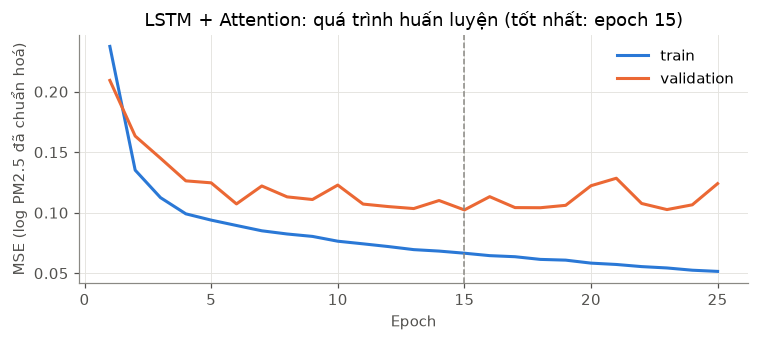

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
epochs = np.arange(1, len(main_history["loss"]) + 1)
ax.plot(epochs, main_history["loss"], color=PALETTE[0], linewidth=2, label="train")
ax.plot(epochs, main_history["val_loss"], color=PALETTE[1], linewidth=2, label="validation")
best = int(np.argmin(main_history["val_loss"])) + 1
ax.axvline(best, color="#8a8984", linestyle="--", linewidth=1)
ax.set(xlabel="Epoch", ylabel="MSE (log PM2.5 đã chuẩn hoá)", title=f"LSTM + Attention: quá trình huấn luyện (tốt nhất: epoch {best})")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "main_learning_curve.png"), bbox_inches="tight")
plt.show()

## 5. Thí nghiệm E1: mô hình học sâu có thắng các mô hình mốc không?

Bốn chỉ số tính trên đơn vị gốc µg/m³ bằng các hàm trong `metrics.py` (slide chương 2.1). R² là bình phương hệ số tương quan Pearson; NSE $= 1 - \frac{\sum (o_i - p_i)^2}{\sum (o_i - \bar o)^2}$ (bằng 1 là hoàn hảo, bằng 0 là ngang đoán trung bình). MAE và RMSE có đơn vị µg/m³, càng nhỏ càng tốt.

In [8]:
def scores(y_true, y_pred):
    return metrics.regression_report(y_true, y_pred)       # {"R2", "NSE", "MAE", "RMSE"}


pred = {"validation": {}, "test": {}}
for split in ["validation", "test"]:
    pred[split]["Giữ nguyên (persistence)"] = data[split]["current"]
    pred[split]["Cùng giờ hôm trước"] = data[split]["yesterday"]
    for label, (model, history) in trained.items():
        pred[split][label] = predict(model, data[split]["X"])

rows = []
for label in pred["test"]:
    model_history = trained.get(label)
    row = {"mô hình": label,
           "số tham số": model_history[0].count_params() if model_history else 0,
           "số epoch (tốt nhất)": (f"{len(model_history[1]['loss'])} ({int(np.argmin(model_history[1]['val_loss'])) + 1})"
                                   if model_history else "–"),
           "RMSE validation": scores(data["validation"]["y_true"], pred["validation"][label])["RMSE"]}
    row.update(scores(data["test"]["y_true"], pred["test"][label]))
    rows.append(row)
e1_table = pd.DataFrame(rows).set_index("mô hình")
e1_table.to_csv(os.path.join(RESULT_DIR, "E1_model_comparison.csv"))
e1_table.style.format({"RMSE validation": "{:.2f}", "R2": "{:.3f}", "NSE": "{:.3f}", "MAE": "{:.2f}", "RMSE": "{:.2f}"})

,số tham số,số epoch (tốt nhất),RMSE validation,R2,NSE,MAE,RMSE
mô hình,,,,,,,
Giữ nguyên (persistence),0,–,13.77,0.779,0.765,10.02,15.55
Cùng giờ hôm trước,0,–,31.21,0.286,0.069,21.16,30.98
Hồi quy tuyến tính,721,42 (32),9.94,0.892,0.891,6.99,10.62
RNN,5185,32 (22),10.67,0.888,0.872,7.51,11.50
GRU,15617,27 (17),9.66,0.899,0.879,7.28,11.16
LSTM,20545,27 (17),10.32,0.904,0.876,7.51,11.29
LSTM 2 lớp,53569,22 (12),10.20,0.890,0.867,7.66,11.72
LSTM + Attention,28929,25 (15),10.17,0.900,0.876,7.37,11.29


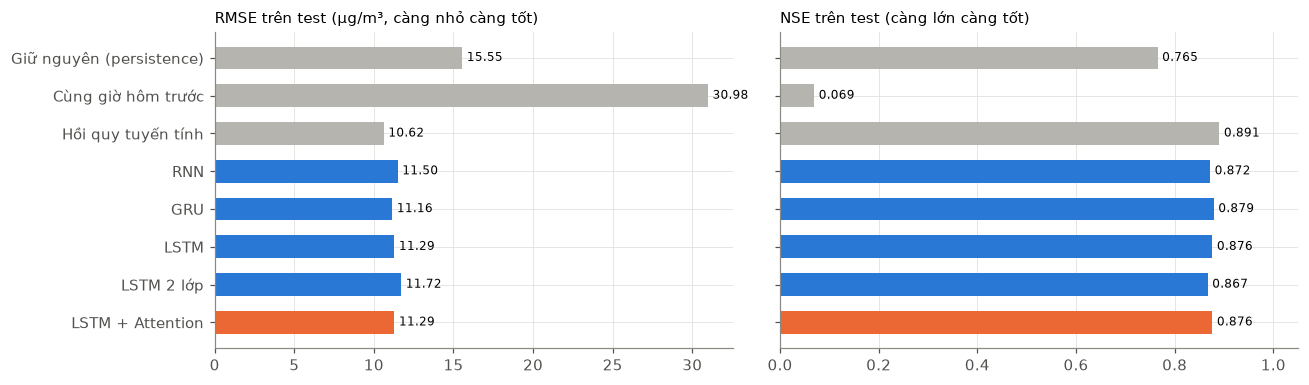

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
labels = list(e1_table.index)
y_pos = np.arange(len(labels))
colors = ["#b5b4ae" if i < 3 else PALETTE[0] for i in range(len(labels))]
colors[labels.index("LSTM + Attention")] = PALETTE[1]
for ax, col, title in [(axes[0], "RMSE", "RMSE trên test (µg/m³, càng nhỏ càng tốt)"), (axes[1], "NSE", "NSE trên test (càng lớn càng tốt)")]:
    bars = ax.barh(y_pos, e1_table[col], color=colors, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.2f}" if col == "RMSE" else f"{v:.3f}" for v in e1_table[col]], padding=3, fontsize=8)
    ax.set_title(title, fontsize=10, loc="left")
axes[0].set_yticks(y_pos, labels)
axes[0].invert_yaxis()
axes[1].set_xlim(0, 1.05)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "E1_model_comparison.png"), bbox_inches="tight")
plt.show()

**Nhận xét E1.**
- **Mọi mô hình có học đều thắng rõ hai mô hình mốc đơn giản.** RMSE test giảm từ 15,55 µg/m³ (giữ nguyên) xuống 10,6–11,7; NSE tăng từ 0,765 lên 0,867–0,891. "Cùng giờ hôm trước" rất kém (NSE 0,07), vì PM2.5 sau 2 giờ giống giờ hiện tại hơn nhiều so với cùng giờ hôm qua.
- **Hồi quy tuyến tính tốt nhất trên test** (RMSE 10,62, NSE 0,891), nhỉnh hơn cả năm biến thể RNN (RMSE 11,16–11,72). Trên validation, GRU tốt nhất (9,66), rồi mới tới hồi quy tuyến tính (9,94). Với tầm dự báo chỉ 2 giờ, PM2.5 sắp tới gần như là một tổ hợp tuyến tính của vài giờ gần nhất, nên mô hình tuyến tính đã nắm được phần lớn thông tin.
- **Năm biến thể RNN chênh nhau ít.** LSTM 2 lớp có nhiều tham số nhất (53.569) nhưng kém nhất và dừng sớm nhất (tốt nhất ở epoch 12): thêm lớp không giúp với lượng dữ liệu này.
- Mục 12 kiểm tra xem các chênh lệch này có đáng tin không; mục 13 (E1b) thử một cách sửa đơn giản, và mục 14 (N1–N10) nâng cấp mô hình qua hai vòng.

## 6. Thí nghiệm E2: dùng bao nhiêu giờ quá khứ?

Mô hình chính được huấn luyện lại với cửa sổ 24 và 72 giờ (proposal: 8, 16, 24 bước 3 giờ, tức 24, 48, 72 giờ). Độ dài cửa sổ được **chọn theo validation**; tập test chỉ để báo cáo.

In [10]:
e2_rows = []
if RUN_EXPERIMENTS:
    for lookback in [24, 48, 72]:
        d = data if lookback == LOOKBACK else make_data(lookback=lookback)
        if lookback == LOOKBACK:
            model, history = main_model, main_history
        else:
            model, history = train_or_load(f"lstm_att_lb{lookback}_seed42",
                                           lambda lookback=lookback: build_model("lstm_att", lookback=lookback), d)
        val = scores(d["validation"]["y_true"], predict(model, d["validation"]["X"]))
        test = scores(d["test"]["y_true"], predict(model, d["test"]["X"]))
        e2_rows.append({"cửa sổ (giờ)": lookback, "RMSE validation": val["RMSE"], "NSE validation": val["NSE"],
                        **{f"{k} test": v for k, v in test.items()}})
    e2_table = pd.DataFrame(e2_rows).set_index("cửa sổ (giờ)")
    e2_table.to_csv(os.path.join(RESULT_DIR, "E2_lookback.csv"))
    display(e2_table.round(3))

lstm_att_lb24_seed42: 25 epoch, tốt nhất ở epoch 15, 1.8 phút


lstm_att_lb72_seed42: 20 epoch, tốt nhất ở epoch 10, 2.6 phút


,RMSE validation,NSE validation,R2 test,NSE test,MAE test,RMSE test
cửa sổ (giờ),,,,,,
24,10.182,0.898,0.899,0.883,7.177,10.988
48,10.171,0.898,0.900,0.876,7.367,11.290
72,10.352,0.895,0.899,0.885,7.146,10.905


**Nhận xét E2.**
- Validation gần như không phân biệt 24 và 48 giờ (RMSE 10,18 và 10,17); 72 giờ kém hơn chút (10,35). Theo quy tắc chọn trên validation, giữ cửa sổ 48 giờ.
- Trên test, 24 và 72 giờ lại nhỉnh hơn 48 giờ (RMSE 10,99 và 10,91 so với 11,29). Chênh lệch này cỡ dao động giữa các seed (mục 9), nên không nói được cửa sổ nào tốt hơn hẳn. Thông tin chính nằm ở vài giờ gần nhất (mục 10), nên độ dài cửa sổ ít quan trọng.

## 7. Thí nghiệm E3: các biến khí tượng có giúp không?

So sánh mô hình chính với cùng kiến trúc nhưng bỏ bớt đặc trưng:
- **đầy đủ:** ô nhiễm + khí tượng + thời gian (15 đặc trưng);
- **bỏ khí tượng:** ô nhiễm + thời gian (9 đặc trưng);
- **chỉ PM2.5:** PM2.5 quá khứ + thời gian (7 đặc trưng).

In [11]:
e3_rows = []
if RUN_EXPERIMENTS:
    for label, features, name in [("đầy đủ (15)", FEATURES, None),
                                  ("bỏ khí tượng (9)", POLLUTION + TIME_FEATURES, "noweather"),
                                  ("chỉ PM2.5 + thời gian (7)", ["pm2_5"] + TIME_FEATURES, "pm25only")]:
        d = data if name is None else make_data(features=features)
        if name is None:
            model = main_model
        else:
            model, _ = train_or_load(f"lstm_att_{name}_seed42",
                                     lambda features=features: build_model("lstm_att", n_features=len(features)), d)
        val = scores(d["validation"]["y_true"], predict(model, d["validation"]["X"]))
        test = scores(d["test"]["y_true"], predict(model, d["test"]["X"]))
        e3_rows.append({"đặc trưng": label, "RMSE validation": val["RMSE"], **{f"{k} test": v for k, v in test.items()}})
    e3_table = pd.DataFrame(e3_rows).set_index("đặc trưng")
    e3_table.to_csv(os.path.join(RESULT_DIR, "E3_features.csv"))
    display(e3_table.round(3))

lstm_att_noweather_seed42: 22 epoch, tốt nhất ở epoch 12, 1.8 phút
lstm_att_pm25only_seed42: 32 epoch, tốt nhất ở epoch 22, 2.4 phút


,RMSE validation,R2 test,NSE test,MAE test,RMSE test
đặc trưng,,,,,
đầy đủ (15),10.171,0.900,0.876,7.367,11.290
bỏ khí tượng (9),9.925,0.890,0.878,7.225,11.195
chỉ PM2.5 + thời gian (7),9.599,0.897,0.897,6.761,10.310


**Nhận xét E3.**
- **Bỏ bớt đặc trưng không làm mô hình kém đi, còn tốt hơn.** Chỉ dùng PM2.5 quá khứ và thời gian cho RMSE validation 9,60 và test 10,31, tốt nhất trong ba cách (đầy đủ: 10,17 và 11,29).
- Với dự báo 2 giờ, thông tin cần thiết gần như đã có trong chính chuỗi PM2.5: EDA cho thấy gió và mưa liên quan rõ tới PM2.5, nhưng tác động đó đã hiện ra trong PM2.5 của các giờ trước. Thêm biến khí tượng chủ yếu làm mô hình dễ học vẹt hơn, nhất là khi validation và test ô nhiễm hơn train (mục 2).
- Đây là kết quả của một seed. Các mục khác vẫn dùng đủ 15 đặc trưng của bộ dữ liệu để so sánh được với nhau; nếu dùng mô hình này cho Task 2 hoặc demo thì nên thử bộ 7 đặc trưng.

## 8. Số unit của lớp LSTM

Proposal dự kiến dò 32, 64 hoặc 128 unit trên tập validation.

In [12]:
unit_rows = []
if RUN_EXPERIMENTS:
    for units in [32, 64, 128]:
        if units == UNITS:
            model = main_model
        else:
            model, _ = train_or_load(f"lstm_att_u{units}_seed42", lambda units=units: build_model("lstm_att", units=units), data)
        val = scores(data["validation"]["y_true"], predict(model, data["validation"]["X"]))
        test = scores(data["test"]["y_true"], predict(model, data["test"]["X"]))
        unit_rows.append({"số unit": units, "số tham số": model.count_params(), "RMSE validation": val["RMSE"],
                          **{f"{k} test": v for k, v in test.items()}})
    unit_table = pd.DataFrame(unit_rows).set_index("số unit")
    unit_table.to_csv(os.path.join(RESULT_DIR, "units.csv"))
    display(unit_table.round(3))

lstm_att_u32_seed42: 34 epoch, tốt nhất ở epoch 24, 2.3 phút


lstm_att_u128_seed42: 22 epoch, tốt nhất ở epoch 12, 1.9 phút


,số tham số,RMSE validation,R2 test,NSE test,MAE test,RMSE test
số unit,,,,,,
32,8321,10.103,0.892,0.857,7.829,12.155
64,28929,10.171,0.900,0.876,7.367,11.290
128,107009,10.254,0.879,0.857,7.862,12.128


**Nhận xét.** 32, 64 và 128 unit cho RMSE validation gần nhau (10,10; 10,17; 10,25). Chênh lệch nhỏ hơn dao động giữa các seed nên coi như ngang nhau, và giữ 64 unit như bản phác thảo Keras trong proposal. Trên test, 64 unit tốt nhất (11,29 so với 12,16 và 12,13). Mô hình 128 unit có 107.009 tham số, gần gấp 4 lần, nhưng không tốt hơn: với khoảng 17.500 mẫu train, mô hình lớn hơn không có lợi.

## 9. Độ ổn định qua 3 seed: attention có thật sự giúp không?

LSTM và LSTM + Attention được huấn luyện thêm với seed 43 và 44, để biết chênh lệch giữa hai mô hình có lớn hơn dao động do khởi tạo ngẫu nhiên không.

In [13]:
seed_rows = []
seed_preds = {"LSTM": {}, "LSTM + Attention": {}}
for label, kind in [("LSTM", "lstm"), ("LSTM + Attention", "lstm_att")]:
    for seed in [42, 43, 44]:
        if seed == SEED:
            model = trained[label][0]
        elif RUN_EXPERIMENTS:
            model, _ = train_or_load(f"{kind}_lb48_seed{seed}", lambda kind=kind: build_model(kind), data, seed=seed)
        else:
            continue
        seed_preds[label][seed] = predict(model, data["test"]["X"])
        seed_rows.append({"mô hình": label, "seed": seed, **scores(data["test"]["y_true"], seed_preds[label][seed])})
seed_table = pd.DataFrame(seed_rows)
seed_summary = seed_table.groupby("mô hình")[["R2", "NSE", "MAE", "RMSE"]].agg(["mean", "std"])
seed_table.to_csv(os.path.join(RESULT_DIR, "seeds.csv"), index=False)
display(seed_table.set_index(["mô hình", "seed"]).round(3))
seed_summary.round(3)

lstm_lb48_seed43: 32 epoch, tốt nhất ở epoch 22, 2.2 phút
lstm_lb48_seed44: 36 epoch, tốt nhất ở epoch 26, 2.5 phút
lstm_att_lb48_seed43: 32 epoch, tốt nhất ở epoch 22, 2.5 phút


lstm_att_lb48_seed44: 29 epoch, tốt nhất ở epoch 19, 2.2 phút


R2    NSE    MAE    RMSE
mô hình          seed                             
LSTM             42    0.904  0.876  7.508  11.289
                 43    0.902  0.866  7.817  11.755
                 44    0.902  0.892  7.036  10.577
LSTM + Attention 42    0.900  0.876  7.367  11.290
                 43    0.901  0.879  7.264  11.182
                 44    0.889  0.874  7.259  11.379

R2           NSE           MAE           RMSE       
                   mean    std   mean    std   mean    std    mean    std
mô hình                                                                  
LSTM              0.903  0.001  0.878  0.013  7.454  0.393  11.207  0.593
LSTM + Attention  0.897  0.006  0.877  0.002  7.297  0.061  11.283  0.098

**Nhận xét.**
- LSTM + Attention rất ổn định qua 3 seed: RMSE 11,28 ± 0,10, NSE 0,877 ± 0,002. LSTM dao động nhiều hơn: RMSE 11,21 ± 0,59 (từ 10,58 tới 11,76).
- Trung bình hai mô hình gần như bằng nhau, nên **attention không làm dự báo chính xác hơn**, nhưng làm kết quả ổn định hơn giữa các lần huấn luyện.

## 10. Mô hình nhìn vào giờ nào? (trọng số attention)

Với mỗi mẫu test, attention cho 48 trọng số $\alpha$ (tổng bằng 1) trên 48 giờ của cửa sổ. Hình dưới vẽ trung bình của các trọng số này theo độ trễ so với giờ hiện tại $t$.

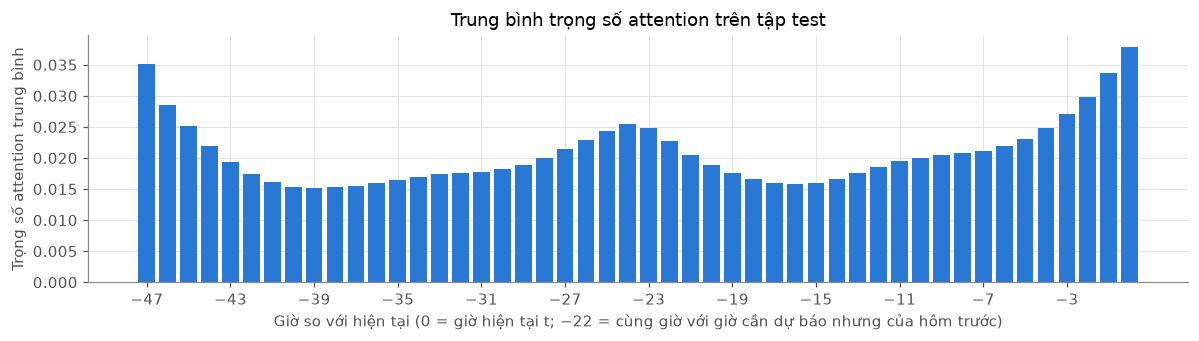

,3 giờ gần nhất (t-2..t),6 giờ gần nhất,quanh cùng giờ hôm trước (t-25..t-19),giờ có trọng số lớn nhất (độ trễ)
giá trị,0.10135,0.17627,0.154399,0.0


In [14]:
att_model = keras.Model(main_model.input, main_model.get_layer("attention").output[1])
alpha = att_model.predict(data["test"]["X"], batch_size=1024, verbose=0)      # (số mẫu, 48)
lag = np.arange(LOOKBACK - 1, -1, -1)                                       # cột cuối = giờ hiện tại (độ trễ 0)
mean_alpha = alpha.mean(axis=0)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(-lag, mean_alpha, color=PALETTE[0], width=0.8)
ax.set(xlabel="Giờ so với hiện tại (0 = giờ hiện tại t; −22 = cùng giờ với giờ cần dự báo nhưng của hôm trước)",
       ylabel="Trọng số attention trung bình", xticks=range(-47, 1, 4),
       title="Trung bình trọng số attention trên tập test")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "attention_by_lag.png"), bbox_inches="tight")
plt.show()

attention_stats = {"3 giờ gần nhất (t-2..t)": float(mean_alpha[-3:].sum()),
                   "6 giờ gần nhất": float(mean_alpha[-6:].sum()),
                   "quanh cùng giờ hôm trước (t-25..t-19)": float(mean_alpha[(lag >= 19) & (lag <= 25)].sum()),
                   "giờ có trọng số lớn nhất (độ trễ)": int(lag[np.argmax(mean_alpha)])}
pd.Series(attention_stats).to_frame("giá trị").T

**Nhận xét.**
- **Trọng số lớn nhất ở giờ hiện tại** (độ trễ 0) và tăng dần trong khoảng 10 giờ gần nhất. 3 giờ gần nhất chiếm 10,1% tổng trọng số, 6 giờ gần nhất 17,6%; nếu chia đều thì chỉ là 6,25% và 12,5%.
- **Có một bướu nhỏ quanh độ trễ 23–25 giờ**, tức cùng giờ của hôm trước: mô hình có dùng chu kỳ ngày mà EDA đã thấy (tự tương quan tăng lại ở 24 giờ).
- **Giờ xa nhất (độ trễ 47) cũng có trọng số cao.** Đây nhiều khả năng là hiệu ứng ở mép cửa sổ: trạng thái LSTM đầu tiên mới đọc 1 giờ nên khác hẳn các trạng thái sau. Không nên hiểu là PM2.5 của 2 ngày trước quan trọng.
- Nhìn chung trọng số khá dàn trải (giờ cao nhất chỉ khoảng 3,8%), khớp với việc attention không làm tăng độ chính xác ở mục 9.

## 11. Phân tích lỗi

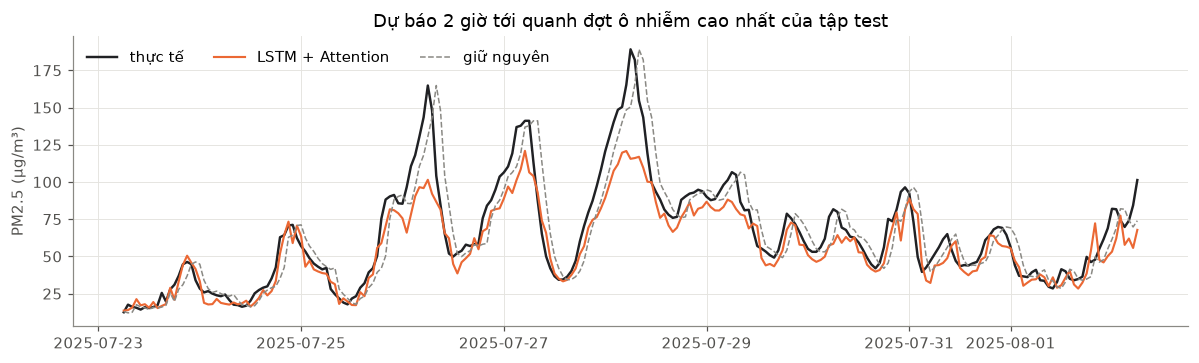

In [15]:
y_test = data["test"]["y_true"]
p_main = pred["test"]["LSTM + Attention"]
p_persist = pred["test"]["Giữ nguyên (persistence)"]
target_time = data["test"]["time"] + pd.Timedelta(hours=HORIZON)

# Đoạn 10 ngày quanh đợt ô nhiễm cao nhất của tập test
peak = target_time[np.argmax(y_test)]
window = (target_time >= peak - pd.Timedelta(days=5)) & (target_time <= peak + pd.Timedelta(days=5))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(target_time[window], y_test[window], color="#202124", linewidth=1.6, label="thực tế")
ax.plot(target_time[window], p_main[window], color=PALETTE[1], linewidth=1.4, label="LSTM + Attention")
ax.plot(target_time[window], p_persist[window], color="#8a8984", linewidth=1, linestyle="--", label="giữ nguyên")
ax.set(ylabel="PM2.5 (µg/m³)", title="Dự báo 2 giờ tới quanh đợt ô nhiễm cao nhất của tập test")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "forecast_example.png"), bbox_inches="tight")
plt.show()

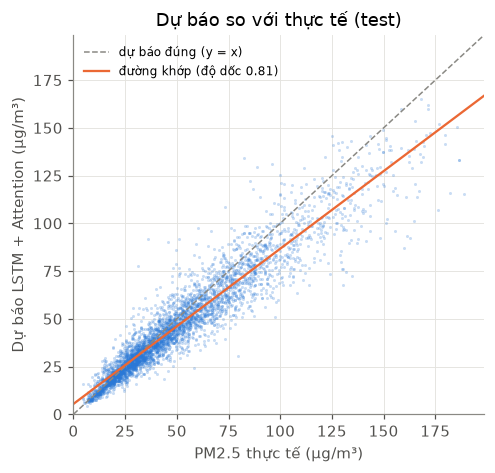

Sai lệch trung bình (dự báo − thực tế) trên cả tập test: -3.98 µg/m³


,so_mau,sai_lech_trung_binh,MAE,MAE_persistence
mức PM2.5 thực tế (µg/m³),,,,
dưới 25,991,0.55,2.58,3.99
25–50,1674,-0.95,4.92,8.25
50–75,901,-5.03,8.50,12.71
trên 75,850,-14.10,16.57,17.70


In [16]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(y_test, p_main, s=4, alpha=0.25, color=PALETTE[0], linewidths=0)
lim = max(y_test.max(), p_main.max()) * 1.05
ax.plot([0, lim], [0, lim], color="#8a8984", linewidth=1, linestyle="--", label="dự báo đúng (y = x)")
slope, intercept = np.polyfit(y_test, p_main, 1)
ax.plot([0, lim], [intercept, intercept + slope * lim], color=PALETTE[1], linewidth=1.5, label=f"đường khớp (độ dốc {slope:.2f})")
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="PM2.5 thực tế (µg/m³)", ylabel="Dự báo LSTM + Attention (µg/m³)",
       title="Dự báo so với thực tế (test)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "scatter_pred_vs_true.png"), bbox_inches="tight")
plt.show()

levels = pd.cut(y_test, [0, 25, 50, 75, 250], labels=["dưới 25", "25–50", "50–75", "trên 75"])
by_level = pd.DataFrame({"mức PM2.5 thực tế (µg/m³)": levels, "sai số": p_main - y_test, "sai số persistence": p_persist - y_test})
level_table = by_level.groupby("mức PM2.5 thực tế (µg/m³)", observed=True).agg(
    so_mau=("sai số", "size"), sai_lech_trung_binh=("sai số", "mean"), MAE=("sai số", lambda e: e.abs().mean()),
    MAE_persistence=("sai số persistence", lambda e: e.abs().mean()))
print(f"Sai lệch trung bình (dự báo − thực tế) trên cả tập test: {np.mean(p_main - y_test):.2f} µg/m³")
level_table.round(2)

In [17]:
month_rows = []
for month in sorted(set(target_time.month)):
    m = target_time.month == month
    month_rows.append({"tháng": month, "số mẫu": int(m.sum()), "PM2.5 trung bình": y_test[m].mean(),
                       "RMSE LSTM + Attention": scores(y_test[m], p_main[m])["RMSE"],
                       "RMSE giữ nguyên": scores(y_test[m], p_persist[m])["RMSE"],
                       "NSE LSTM + Attention": scores(y_test[m], p_main[m])["NSE"]})
month_table = pd.DataFrame(month_rows).set_index("tháng")
month_table.to_csv(os.path.join(RESULT_DIR, "error_by_month.csv"))
month_table.round(2)

,số mẫu,PM2.5 trung bình,RMSE LSTM + Attention,RMSE giữ nguyên,NSE LSTM + Attention
tháng,,,,,
7,744,58.22,14.01,16.55,0.82
8,744,48.89,12.33,13.40,0.82
9,720,48.90,12.30,16.63,0.85
10,744,41.10,9.46,14.19,0.89
11,720,41.80,8.34,15.64,0.93
12,744,61.94,10.24,16.64,0.91


**Nhận xét.**
- **Dự báo theo kịp xu hướng nhưng hụt ở đỉnh.** Ở đợt ô nhiễm cao nhất của tập test (cuối tháng 7/2025), đường dự báo lên xuống gần như cùng lúc với thực tế, không bị trễ 2 giờ như "giữ nguyên". Nhưng đỉnh 189 µg/m³ chỉ được dự báo khoảng 120.
- **Bụi càng cao, dự báo càng thấp hơn thực tế.** Đường khớp ở hình phân tán có độ dốc 0,81. Sai lệch trung bình là −14,1 µg/m³ khi PM2.5 thực tế trên 75, nhưng chỉ +0,6 khi dưới 25; trên cả tập test, dự báo thấp hơn thực tế 4,0 µg/m³.
- Hai nguyên nhân có thể: (1) mô hình học trên log PM2.5, và đổi ngược từ log làm dự báo nghiêng về phía thấp; (2) train có ít giờ ô nhiễm nặng hơn validation và test (mục 2).
- Ở mọi mức PM2.5 và mọi tháng, mô hình đều tốt hơn "giữ nguyên". RMSE cao nhất ở tháng 7 (14,0) và thấp nhất ở tháng 11 (8,3); NSE theo tháng từ 0,82 đến 0,93.

## 12. Các chênh lệch có đáng tin không? (bootstrap theo ngày)

Các giờ liền nhau trong một ngày rất giống nhau, nên không thể coi 4.416 giờ của tập test là 4.416 mẫu độc lập. Nhóm dùng **bootstrap theo ngày**: lấy ngẫu nhiên có hoàn lại 184 ngày từ các ngày của tập test, tính lại chỉ số trên tất cả các giờ của những ngày được chọn, lặp 2.000 lần. Khi so hai mô hình, mỗi lần lấy mẫu dùng cùng các ngày cho cả hai; nếu khoảng tin cậy 95% của chênh lệch không chứa 0 thì chênh lệch đó khó là do may rủi.

In [18]:
B = 2000
days = target_time.normalize()
day_list = days.unique()
day_index = [np.flatnonzero(days == d) for d in day_list]
rng = np.random.default_rng(0)
boot_samples = [np.concatenate([day_index[i] for i in rng.integers(0, len(day_list), len(day_list))]) for _ in range(B)]


def boot_ci(pred_a, pred_b, metric):
    diffs = [scores(y_test[idx], pred_a[idx])[metric] - scores(y_test[idx], pred_b[idx])[metric] for idx in boot_samples]
    return np.percentile(diffs, [2.5, 97.5])


boot_rows = []
for name_a, name_b in [("LSTM + Attention", "Giữ nguyên (persistence)"), ("LSTM + Attention", "Hồi quy tuyến tính"),
                       ("LSTM + Attention", "LSTM"), ("LSTM + Attention", "GRU")]:
    for metric in ["RMSE", "MAE", "NSE"]:
        a, b = pred["test"][name_a], pred["test"][name_b]
        diff = scores(y_test, a)[metric] - scores(y_test, b)[metric]
        lo, hi = boot_ci(a, b, metric)
        boot_rows.append({"so sánh": f"{name_a} so với {name_b}", "chỉ số": metric, "chênh lệch": diff,
                          "khoảng tin cậy 95%": f"{lo:+.3f} đến {hi:+.3f}",
                          "khác 0 rõ ràng?": "có" if lo > 0 or hi < 0 else "chưa chắc"})
boot_table = pd.DataFrame(boot_rows).set_index(["so sánh", "chỉ số"])
boot_table.to_csv(os.path.join(RESULT_DIR, "bootstrap_differences.csv"))
boot_table.style.format({"chênh lệch": "{:+.3f}"})

**Nhận xét.**
- **Thắng "giữ nguyên" là chắc chắn.** RMSE giảm 4,26 µg/m³ (khoảng tin cậy 95%: giảm từ 3,57 đến 4,96), NSE tăng 0,111.
- **Thua hồi quy tuyến tính cũng là thật, dù nhỏ.** RMSE cao hơn 0,67 µg/m³ (từ +0,05 đến +1,27); khoảng tin cậy của cả ba chỉ số đều không chứa 0.
- **So với LSTM và GRU thì chưa phân định được:** khoảng tin cậy của cả ba chỉ số đều chứa 0.

## 13. Thí nghiệm E1b (bổ sung cho E1): cho mạng chỉ học phần thay đổi

Mục 5 và 12 cho thấy ở tầm 2 giờ, các mạng RNN chưa thắng được hồi quy tuyến tính. Một lý do có thể: muốn dự báo đúng, mạng phải tự "chép lại" PM2.5 hiện tại qua nhiều lớp phi tuyến rồi mới cộng phần thay đổi, trong khi hồi quy tuyến tính chỉ cần một trọng số cho giờ hiện tại.

Cách sửa đơn giản là cộng thẳng PM2.5 của giờ hiện tại vào đầu ra (một **kết nối tắt**, giống khối residual của ResNet ở chương 5.2), để mạng chỉ phải học **phần thay đổi trong 2 giờ**:

$$\hat y_{t+2} = \text{PM2.5}_t + f(\text{cửa sổ 48 giờ})$$

Mọi đại lượng đều tính trên PM2.5 đã log và chuẩn hoá. Dữ liệu, kiến trúc bên trong và cách huấn luyện giữ nguyên như mục 3–4. LSTM + Attention chạy 3 seed; GRU và LSTM chạy 1 seed. Vẫn **chọn theo validation**; test chỉ để báo cáo.

In [19]:
def build_residual(kind):
    base = build_model(kind)                                              # mạng như mục 3: đầu ra giờ là phần thay đổi
    i = FEATURES.index("pm2_5")
    pm_now = base.input[:, -1, i:i + 1]                                   # PM2.5 (log, chuẩn hoá) của giờ hiện tại t
    return keras.Model(base.input, layers.Add()([pm_now, base.output]), name=kind + "_res")


e1b_rows, e1b_pred = [], {}
if RUN_EXPERIMENTS:
    for label, kind, seeds in [("LSTM + Attention", "lstm_att", [42, 43, 44]), ("GRU", "gru", [42]), ("LSTM", "lstm", [42])]:
        for seed in seeds:
            model, _ = train_or_load(f"{kind}_res_lb48_seed{seed}", lambda kind=kind: build_residual(kind), data, seed=seed)
            val = scores(data["validation"]["y_true"], predict(model, data["validation"]["X"]))
            e1b_pred[(label, seed)] = predict(model, data["test"]["X"])
            e1b_rows.append({"mô hình": label + " (học phần thay đổi)", "seed": seed, "RMSE validation": val["RMSE"],
                            **{f"{k} test": v for k, v in scores(y_test, e1b_pred[(label, seed)]).items()}})
    e1b_table = pd.DataFrame(e1b_rows).set_index(["mô hình", "seed"])
    e1b_table.to_csv(os.path.join(RESULT_DIR, "E1b_residual.csv"))
    display(e1b_table.round(3))

lstm_att_res_lb48_seed42: 23 epoch, tốt nhất ở epoch 13, 2.6 phút
lstm_att_res_lb48_seed43: 19 epoch, tốt nhất ở epoch 9, 1.9 phút


lstm_att_res_lb48_seed44: 18 epoch, tốt nhất ở epoch 8, 1.4 phút
gru_res_lb48_seed42: 27 epoch, tốt nhất ở epoch 17, 2.1 phút


lstm_res_lb48_seed42: 23 epoch, tốt nhất ở epoch 13, 1.7 phút


RMSE validation  R2 test  NSE test  \
mô hình                              seed                                       
LSTM + Attention (học phần thay đổi) 42              9.546    0.873     0.871   
                                     43              9.662    0.880     0.864   
                                     44              9.530    0.876     0.863   
GRU (học phần thay đổi)              42              9.273    0.895     0.885   
LSTM (học phần thay đổi)             42              9.906    0.874     0.864   

                                           MAE test  RMSE test  
mô hình                              seed                       
LSTM + Attention (học phần thay đổi) 42       7.463     11.550  
                                     43       7.753     11.848  
                                     44       7.763     11.894  
GRU (học phần thay đổi)              42       7.151     10.900  
LSTM (học phần thay đổi)             42       7.691     11.829

So sánh trung bình 3 seed của LSTM + Attention có và không có kết nối tắt, cùng với hồi quy tuyến tính. Sau đó dùng lại bootstrap theo ngày của mục 12 (seed 42) cho LSTM + Attention và GRU, mỗi mô hình so với bản không có kết nối tắt và với hồi quy tuyến tính.

In [20]:
if RUN_EXPERIMENTS:
    cols = ["R2", "NSE", "MAE", "RMSE"]
    plain = seed_table[seed_table["mô hình"] == "LSTM + Attention"][cols].mean()               # 3 seed, mục 9
    res = e1b_table.loc["LSTM + Attention (học phần thay đổi)"][[c + " test" for c in cols]].mean()
    res.index = cols
    linear = pd.Series(scores(y_test, pred["test"]["Hồi quy tuyến tính"]))[cols]
    compare = pd.DataFrame([plain, res, linear], index=["LSTM + Attention (3 seed)",
                                                        "LSTM + Attention học phần thay đổi (3 seed)", "Hồi quy tuyến tính"])
    display(compare.round(3))

    e1b_boot_rows = []
    for label, name_b in [("LSTM + Attention", "LSTM + Attention"), ("LSTM + Attention", "Hồi quy tuyến tính"),
                          ("GRU", "GRU"), ("GRU", "Hồi quy tuyến tính")]:
        a, b = e1b_pred[(label, 42)], pred["test"][name_b]                   # seed 42 của cả hai
        for metric in ["RMSE", "MAE", "NSE"]:
            lo, hi = boot_ci(a, b, metric)
            e1b_boot_rows.append({"so sánh": f"{label} học phần thay đổi so với {name_b}", "chỉ số": metric,
                                 "chênh lệch": scores(y_test, a)[metric] - scores(y_test, b)[metric],
                                 "khoảng tin cậy 95%": f"{lo:+.3f} đến {hi:+.3f}",
                                 "khác 0 rõ ràng?": "có" if lo > 0 or hi < 0 else "chưa chắc"})
    e1b_boot = pd.DataFrame(e1b_boot_rows).set_index(["so sánh", "chỉ số"])
    e1b_boot.to_csv(os.path.join(RESULT_DIR, "E1b_bootstrap.csv"))
    display(e1b_boot.style.format({"chênh lệch": "{:+.3f}"}))

,R2,NSE,MAE,RMSE
LSTM + Attention (3 seed),0.897,0.877,7.297,11.283
LSTM + Attention học phần thay đổi (3 seed),0.876,0.866,7.660,11.764
Hồi quy tuyến tính,0.892,0.891,6.985,10.621


**Nhận xét E1b.**
- **Trên validation, học phần thay đổi giúp rõ và đều:** LSTM + Attention từ 10,17 xuống 9,53–9,66 (3 seed); GRU từ 9,66 xuống 9,27, thấp nhất trong mọi mô hình của notebook (hồi quy tuyến tính: 9,94).
- **Với GRU, cải thiện giữ được trên test:** RMSE giảm 0,26 (khoảng tin cậy 95%: từ −0,49 đến −0,03), còn 10,90, NSE 0,885. Chênh lệch với hồi quy tuyến tính chỉ còn +0,28 (từ −0,07 đến +0,64), tức chưa phân biệt được hai mô hình.
- **Với LSTM + Attention thì không:** RMSE test trung bình 3 seed là 11,76 ± 0,19, so với 11,28 ± 0,10 của bản thường. Với seed 42, chênh lệch +0,26 chưa chắc khác 0, và vẫn kém hồi quy tuyến tính rõ ràng.
- Validation (01–06/2025) và test (07–12/2025) khác nhau khá nhiều, nên một thay đổi tốt trên validation chưa chắc tốt trên test. Nếu chọn hoàn toàn theo validation thì mô hình tốt nhất là **GRU học phần thay đổi**: trên test nó ngang hồi quy tuyến tính nhưng chưa vượt được.

## 14. Nâng cấp mô hình (N1–N10)

Các mục trên cho thấy ở tầm 2 giờ, mạng RNN chưa thắng được hồi quy tuyến tính. Phần này thử sáu cách nâng cấp:

| Mã | Nâng cấp | Câu hỏi |
|---|---|---|
| N1 | Bộ đặc trưng gọn; mạng học phần thay đổi; GRU hay LSTM | Ít biến hơn và kết nối tắt có giúp không? |
| N6 | Thêm dữ liệu: train từ 08/2022, thêm 10 biến (hướng gió, CO, SO2, O3, bụi, AOD, điểm sương, mây, bức xạ) | Nhiều dữ liệu, nhiều biến hơn có giúp không? |
| N5 | Dò siêu tham số đầy đủ: cửa sổ × số unit × số lớp | Cấu hình nào tốt nhất? |
| N2 | Hiệu chỉnh sai lệch khi đổi ngược từ log (smearing) | Bớt dự báo thấp được không? |
| N3 | Gộp 3 seed; gộp với hồi quy tuyến tính | Gộp có giúp không? |
| N4 | Huấn luyện lại trên train + validation | Thêm 6 tháng gần nhất có giúp không? |

**Cách làm: bậc thang.** Làm lần lượt N1 → N6 → N5 → N2 → N3 → N4; bậc sau dùng lựa chọn của bậc trước. Mọi lựa chọn dựa trên **validation**, tập test chỉ để báo cáo. Hồi quy tuyến tính cũng được nâng cấp tương ứng (chọn đặc trưng, cửa sổ, dữ liệu, hiệu chỉnh sai lệch, huấn luyện lại) để phép so sánh cuối cùng công bằng. Ngoài tập test 07–12/2025, mô hình cuối được kiểm tra thêm trên 01–10/2026, giai đoạn có trọn một mùa đông. Mục 14.1–14.9 là vòng 1 (N1–N6); mục 14.10–14.13 là vòng 2 (N7–N10) và phần ước lượng còn nâng cấp được bao nhiêu.

### 14.1. Dữ liệu mở rộng

File `hanoi_hourly_2022_2026_v2.csv` được tải bằng script của nhóm qua `FinalDeepData/task1_2/download_2022_2026.py`, cùng hai ô lưới và cùng độ cao 19 m như bộ v1, nên các cột chung trùng khớp hoàn toàn với bộ v1 (kiểm tra bằng `assert` ở dưới). Bộ này dài hơn (08/2022–10/2026) và có thêm 10 biến; có hướng gió nên gió được đổi thành hai thành phần u, v. Validation và test giữ nguyên như mục 2 để so sánh được; phần 01–10/2026 chỉ dùng để kiểm tra thêm.

In [21]:
SEEDS3 = [42, 43, 44]
N1_ARCHS = {"LSTM + Attention": dict(cell="lstm", attention=True),
            "GRU + Attention": dict(cell="gru", attention=True),
            "GRU": dict(cell="gru", attention=False)}
FEATURE_SETS = {"F7": ["pm2_5"] + TIME_FEATURES,        # PM2.5 + thời gian
                "F9": POLLUTION + TIME_FEATURES,         # 3 chất ô nhiễm + thời gian
                "F15": FEATURES}                         # đủ 15 đặc trưng như mục 2
N1_FEATS = list(FEATURE_SETS)
EXTRA = ["carbon_monoxide", "sulphur_dioxide", "ozone", "dust", "aerosol_optical_depth",
         "dew_point_2m", "cloud_cover", "shortwave_radiation", "wind_u", "wind_v"]        # 10 biến mới
FEATS = {**FEATURE_SETS, **{name + "+X": cols + EXTRA for name, cols in FEATURE_SETS.items()}}
N5_GRID = [(L, U, N) for L in (24, 48, 72) for U in (32, 64, 128) for N in (1, 2)]
LIN_LOOKBACKS = (24, 48, 72)

ext = load_hourly(os.path.join(DATA_ROOT, "task1_2", "hanoi_hourly_2022_2026_v2.csv")).drop(columns="split")
ext = ext.loc[ext.dropna().index.min():]                    # CAMS có số từ 7 giờ ngày 4/8/2022
assert not ext.isna().any().any()
theta = np.deg2rad(ext["wind_direction_10m"])               # hướng gió thổi tới, tính bằng độ
ext["wind_u"] = -ext["wind_speed_10m"] * np.sin(theta)      # dương: gió thổi về phía đông
ext["wind_v"] = -ext["wind_speed_10m"] * np.cos(theta)      # dương: gió thổi về phía bắc
t = ext.index
ext_split = pd.Series(np.select([t < "2025-01-01", t < "2025-07-01", t < "2026-01-01"],
                                ["train", "validation", "test"], "test_2026"), index=t)
common = df.index.intersection(ext.index)
assert all(np.allclose(df.loc[common, c], ext.loc[common, c]) for c in POLLUTION + WEATHER)   # trùng bộ v1


def make_dataset(frame, columns, log_columns, split, ref=None):
    # Đặc trưng như mục 2.1; trung bình, độ lệch chuẩn tính trên tập train (hoặc lấy của bộ ref)
    feat = frame[columns].copy()
    for c in log_columns:
        if c in feat:
            feat[c] = np.log1p(feat[c])
    for name, period, value in [("hour", 24, frame.index.hour), ("dow", 7, frame.index.dayofweek),
                                ("doy", 365.25, frame.index.dayofyear - 1)]:
        feat[name + "_sin"] = np.sin(2 * np.pi * value / period)
        feat[name + "_cos"] = np.cos(2 * np.pi * value / period)
    ref = ref or {"mean": feat[split == "train"].mean(), "std": feat[split == "train"].std()}
    out = (feat - ref["mean"][feat.columns]) / ref["std"][feat.columns]
    out["split"] = split
    return {"frame": frame, "scaled": out, "mean": ref["mean"], "std": ref["std"]}


EXT_LOG = LOG_COLUMNS + ["carbon_monoxide", "sulphur_dioxide", "ozone", "dust", "aerosol_optical_depth"]
ds_v1 = make_dataset(df, POLLUTION + WEATHER, LOG_COLUMNS, df["split"])
ds_ext = make_dataset(ext, POLLUTION + WEATHER + EXTRA, EXT_LOG, ext_split)
ds_v1_2026 = make_dataset(ext, POLLUTION + WEATHER, LOG_COLUMNS, ext_split, ref=ds_v1)   # để mô hình bộ v1 dự báo năm 2026
DATASETS = {"v1": ds_v1, "ext": ds_ext}
assert np.allclose(ds_v1["scaled"][FEATURES].to_numpy(), scaled[FEATURES].to_numpy())  # giống hệt mục 2
print("Bộ mở rộng:", ext.index.min(), "đến", ext.index.max(), "|", len(ext), "giờ,", len(ext.columns), "cột")
print("Số giờ mỗi phần:", ext_split.value_counts().reindex(["train", "validation", "test", "test_2026"]).to_dict())

Bộ mở rộng: 2022-08-04 07:00:00 đến 2026-10-31 23:00:00 | 37193 giờ, 21 cột
Số giờ mỗi phần: {'train': 21137, 'validation': 4344, 'test': 4416, 'test_2026': 7296}


In [22]:
def build_general(cell, attention, residual, units, n_layers, n_features, lookback):
    # GRU hoặc LSTM, 1–2 lớp, có hoặc không attention, có hoặc không kết nối tắt (học phần thay đổi)
    RNN = {"gru": layers.GRU, "lstm": layers.LSTM}[cell]
    inp = keras.Input(shape=(lookback, n_features), name="window")
    z = inp
    for _ in range(n_layers - 1):
        z = RNN(units, return_sequences=True)(z)                       # lớp dưới trả về cả dãy
    if attention:
        H = RNN(units, return_sequences=True)(z)
        h_last = H[:, -1, :]
        context, _ = BahdanauAttention(units, name="attention")(h_last, H)
        z = layers.Concatenate()([context, h_last])
    else:
        z = RNN(units)(z)
    out = layers.Dense(1)(layers.Dropout(0.2)(z))
    if residual:
        out = layers.Add()([inp[:, -1, 0:1], out])                      # cột 0 luôn là PM2.5 của giờ hiện tại
    return keras.Model(inp, out)


ARCH_NAME = {("lstm", True): "LSTM + Attention", ("gru", True): "GRU + Attention", ("gru", False): "GRU"}


def describe(sp):
    if sp["kind"] == "linear":
        return f"Hồi quy tuyến tính, {sp['feat']}, cửa sổ {sp['lookback']} giờ, bộ {sp['data']}"
    return (f"{ARCH_NAME[(sp['cell'], sp['attention'])]}{' học phần thay đổi' if sp['residual'] else ''}, "
            f"{sp['feat']}, cửa sổ {sp['lookback']} giờ, {sp['units']} unit, {sp['layers']} lớp, bộ {sp['data']}")


def run_name(sp, seed):
    if sp["kind"] == "linear":
        return f"n_{sp['data']}_linear_{sp['feat']}_lb{sp['lookback']}_seed{seed}"
    return (f"n_{sp['data']}_{sp['cell']}{'att' if sp['attention'] else ''}{'_res' if sp['residual'] else ''}_"
            f"{sp['feat']}_lb{sp['lookback']}_u{sp['units']}_l{sp['layers']}_seed{seed}")


def model_fn(sp):
    n_features = len(FEATS[sp["feat"]])
    if sp["kind"] == "linear":
        return lambda: build_model("linear", n_features=n_features, lookback=sp["lookback"])
    return lambda: build_general(sp["cell"], sp["attention"], sp["residual"], sp["units"], sp["layers"],
                                 n_features, sp["lookback"])


def windows_of(sp, ds=None):
    ds = ds or DATASETS[sp["data"]]
    w = make_windows(ds["scaled"], FEATS[sp["feat"]], "pm2_5", lookback=sp["lookback"], horizons=(HORIZON,))
    out = {}
    for split in pd.unique(w["split"]):
        m = w["split"] == split
        t = pd.DatetimeIndex(w["time"][m])
        out[split] = {"X": w["X"][m], "y": w["y"][m], "time": t,
                      "y_true": ds["frame"]["pm2_5"].reindex(t + pd.Timedelta(hours=HORIZON)).to_numpy()}
    return out


def predictions(model, sp, d):
    # Dự báo log(1 + PM2.5) ở mọi tập, theo giờ hiện tại t; mô hình bộ v1 dự báo năm 2026 qua bộ mở rộng
    ds = DATASETS[sp["data"]]
    parts = dict(d)
    if "test_2026" not in parts:
        parts["test_2026"] = windows_of(sp, ds_v1_2026)["test_2026"]
    log, truth = {}, {}
    for split, part in parts.items():
        z = model.predict(part["X"], batch_size=1024, verbose=0)[:, 0]
        log[split] = pd.Series(z * ds["std"]["pm2_5"] + ds["mean"]["pm2_5"], index=part["time"])
        truth[split] = pd.Series(part["y_true"], index=part["time"])
    return log, truth


def run(sp, seed=SEED):
    d = windows_of(sp)
    model, history = train_or_load(run_name(sp, seed), model_fn(sp), d, seed=seed)
    log, truth = predictions(model, sp, d)
    return {"spec": sp, "seed": seed, "best_epoch": int(np.argmin(history["val_loss"])) + 1, "log": log, "truth": truth}


def ugm3(log_pred, k=1.0):
    return k * np.exp(log_pred) - 1                             # log(1 + PM2.5) về µg/m³, k: hệ số hiệu chỉnh (N2)


def smear_factor(log_pred, truth):
    a, b = log_pred.align(truth, join="inner")
    return float(np.mean(np.exp(np.log1p(b) - a)))              # trung bình e^(phần dư trên thang log), Duan (1983)


def rmse_of(r, split="validation", k=1.0):
    return scores(r["truth"][split], ugm3(r["log"][split], k))["RMSE"]


def mean_log(runs, split):
    return sum(r["log"][split] for r in runs) / len(runs)      # gộp các seed: trung bình trên thang log


def blend(a, b, w):
    if w == 1:
        return a
    if w == 0:
        return b
    j = pd.concat([a, b], axis=1, join="inner")
    return w * j.iloc[:, 0] + (1 - w) * j.iloc[:, 1]

### 14.2. N1: bộ đặc trưng gọn và học phần thay đổi

Ba kiến trúc (LSTM + Attention, GRU + Attention, GRU) × có hoặc không học phần thay đổi × ba bộ đặc trưng (F7: PM2.5 + thời gian; F9: thêm PM10 và NO2; F15: đủ 15 đặc trưng), cùng cửa sổ 48 giờ, 64 unit, seed 42. Hai cấu hình có RMSE validation thấp nhất được chạy thêm seed 43 và 44, rồi chọn theo trung bình 3 seed.

In [23]:
n1_rows = []
if RUN_EXPERIMENTS:
    for arch_label, arch in N1_ARCHS.items():
        for residual in (False, True):
            for feat in N1_FEATS:
                sp = dict(kind="rnn", data="v1", feat=feat, lookback=LOOKBACK, units=UNITS, layers=1,
                          residual=residual, **arch)
                n1_rows.append({"spec": sp, "kiến trúc": arch_label, "học phần thay đổi": "có" if residual else "không",
                                "đặc trưng": feat, "RMSE validation": rmse_of(run(sp))})
    n1_table = pd.DataFrame(n1_rows).sort_values("RMSE validation").reset_index(drop=True)
    n1_table.drop(columns="spec").to_csv(os.path.join(RESULT_DIR, "N1_screening.csv"), index=False)
    display(n1_table.drop(columns="spec").round(3))

n_v1_lstmatt_F7_lb48_u64_l1_seed42: 32 epoch, tốt nhất ở epoch 22, 2.4 phút


n_v1_lstmatt_F9_lb48_u64_l1_seed42: 22 epoch, tốt nhất ở epoch 12, 1.6 phút


n_v1_lstmatt_F15_lb48_u64_l1_seed42: 25 epoch, tốt nhất ở epoch 15, 1.9 phút


n_v1_lstmatt_res_F7_lb48_u64_l1_seed42: 29 epoch, tốt nhất ở epoch 19, 2.2 phút


n_v1_lstmatt_res_F9_lb48_u64_l1_seed42: 24 epoch, tốt nhất ở epoch 14, 1.8 phút


n_v1_lstmatt_res_F15_lb48_u64_l1_seed42: 23 epoch, tốt nhất ở epoch 13, 1.8 phút


... (9 outputs left out)

n_v1_gru_res_F7_lb48_u64_l1_seed42: 30 epoch, tốt nhất ở epoch 20, 2.2 phút


n_v1_gru_res_F9_lb48_u64_l1_seed42: 29 epoch, tốt nhất ở epoch 19, 2.1 phút


n_v1_gru_res_F15_lb48_u64_l1_seed42: 27 epoch, tốt nhất ở epoch 17, 2.0 phút


,kiến trúc,học phần thay đổi,đặc trưng,RMSE validation
0,GRU + Attention,có,F15,9.059
1,GRU + Attention,có,F9,9.222
2,GRU,không,F9,9.245
3,GRU,có,F15,9.273
4,GRU,có,F9,9.456
5,GRU + Attention,không,F7,9.488
6,LSTM + Attention,có,F15,9.546
7,LSTM + Attention,có,F9,9.578
8,GRU + Attention,không,F15,9.597
9,LSTM + Attention,không,F7,9.599


In [24]:
if RUN_EXPERIMENTS:
    n1_runs, n1_seed_rows = {}, []
    for sp in n1_table["spec"].head(2):
        runs = [run(sp, s) for s in SEEDS3]
        n1_runs[describe(sp)] = runs
        v = [rmse_of(r) for r in runs]
        n1_seed_rows.append({"cấu hình": describe(sp), "RMSE validation TB": np.mean(v), "độ lệch chuẩn": np.std(v, ddof=1)})
    n1_seed_table = pd.DataFrame(n1_seed_rows).set_index("cấu hình")
    n1_seed_table.to_csv(os.path.join(RESULT_DIR, "N1_three_seeds.csv"))
    best1 = n1_runs[n1_seed_table["RMSE validation TB"].idxmin()][0]["spec"]
    display(n1_seed_table.round(3))
    print("Chọn sau N1:", describe(best1))

n_v1_gruatt_res_F15_lb48_u64_l1_seed42: 23 epoch, tốt nhất ở epoch 13, 1.8 phút


n_v1_gruatt_res_F15_lb48_u64_l1_seed43: 20 epoch, tốt nhất ở epoch 10, 1.6 phút


n_v1_gruatt_res_F15_lb48_u64_l1_seed44: 25 epoch, tốt nhất ở epoch 15, 2.0 phút


n_v1_gruatt_res_F9_lb48_u64_l1_seed42: 27 epoch, tốt nhất ở epoch 17, 2.2 phút


n_v1_gruatt_res_F9_lb48_u64_l1_seed43: 23 epoch, tốt nhất ở epoch 13, 1.9 phút


n_v1_gruatt_res_F9_lb48_u64_l1_seed44: 23 epoch, tốt nhất ở epoch 13, 1.9 phút


,RMSE validation TB,độ lệch chuẩn
cấu hình,,
"GRU + Attention học phần thay đổi, F15, cửa sổ 48 giờ, 64 unit, 1 lớp, bộ v1",9.201,0.141
"GRU + Attention học phần thay đổi, F9, cửa sổ 48 giờ, 64 unit, 1 lớp, bộ v1",9.260,0.037


Chọn sau N1: GRU + Attention học phần thay đổi, F15, cửa sổ 48 giờ, 64 unit, 1 lớp, bộ v1


**Nhận xét N1.**
- **GRU tốt hơn LSTM:** với cùng cấu trúc có attention, GRU + Attention thắng LSTM + Attention ở cả 6 cặp (3 bộ đặc trưng × có hoặc không học phần thay đổi). GRU + Attention học phần thay đổi với đủ 15 đặc trưng có RMSE validation thấp nhất (9,06), so với 10,17 của mô hình chính ban đầu.
- **Học phần thay đổi giúp cả ba kiến trúc khi dùng đủ 15 đặc trưng:** LSTM + Attention giảm từ 10,17 xuống 9,55; GRU + Attention từ 9,60 xuống 9,06; GRU từ 9,67 xuống 9,27.
  - **Với F7 thì không giúp:** cả ba kiến trúc đều kém đi chút ít.
  - **Với F9 thì tuỳ kiến trúc.**
  - Một cách giải thích: khi có nhiều biến khí tượng, kết nối tắt giúp mạng khỏi phải tự "chép lại" PM2.5 hiện tại giữa các biến khác.
- Các cấu hình trùng với thí nghiệm trước cho đúng số cũ (E3: 9,60, 9,93, 10,17; E1b: 9,55 và 9,27), nên kết quả tái lập được.
- Chạy 3 seed cho hai cấu hình đầu: F15 (9,20 ± 0,14) và F9 (9,26 ± 0,04) gần như ngang nhau; chọn F15 theo trung bình.

### 14.3. N6: thêm dữ liệu

Giữ cấu hình đã chọn ở N1 và so ba cách lấy dữ liệu, mỗi cách 3 seed:
- bộ v1, train 2023–2024;
- bộ mở rộng, train từ 08/2022 đến hết 2024 (thêm khoảng 3.600 giờ);
- bộ mở rộng, thêm 10 biến mới.

In [25]:
if RUN_EXPERIMENTS:
    variants = {"v1, train 2023–2024": best1,
                "mở rộng, train 08/2022–2024": {**best1, "data": "ext"},
                "mở rộng + 10 biến mới": {**best1, "data": "ext", "feat": best1["feat"] + "+X"}}
    n6_runs, n6_rows = {}, []
    for label, sp in variants.items():
        runs = [run(sp, s) for s in SEEDS3]
        n6_runs[label] = runs
        v = [rmse_of(r) for r in runs]
        n6_rows.append({"dữ liệu": label, "số đặc trưng": len(FEATS[sp["feat"]]), "số mẫu train": len(runs[0]["log"]["train"]),
                        "RMSE validation TB": np.mean(v), "độ lệch chuẩn": np.std(v, ddof=1)})
    n6_table = pd.DataFrame(n6_rows).set_index("dữ liệu")
    n6_table.to_csv(os.path.join(RESULT_DIR, "N6_data.csv"))
    best6_label = n6_table["RMSE validation TB"].idxmin()
    best6 = n6_runs[best6_label][0]["spec"]
    display(n6_table.round(3))
    print("Chọn sau N6:", describe(best6))

n_v1_gruatt_res_F15_lb48_u64_l1_seed42: 23 epoch, tốt nhất ở epoch 13, 1.8 phút


n_v1_gruatt_res_F15_lb48_u64_l1_seed43: 20 epoch, tốt nhất ở epoch 10, 1.6 phút


n_v1_gruatt_res_F15_lb48_u64_l1_seed44: 25 epoch, tốt nhất ở epoch 15, 2.0 phút


n_ext_gruatt_res_F15_lb48_u64_l1_seed42: 22 epoch, tốt nhất ở epoch 12, 2.1 phút


n_ext_gruatt_res_F15_lb48_u64_l1_seed43: 28 epoch, tốt nhất ở epoch 18, 2.7 phút


n_ext_gruatt_res_F15_lb48_u64_l1_seed44: 23 epoch, tốt nhất ở epoch 13, 2.2 phút


n_ext_gruatt_res_F15+X_lb48_u64_l1_seed42: 19 epoch, tốt nhất ở epoch 9, 1.8 phút


n_ext_gruatt_res_F15+X_lb48_u64_l1_seed43: 20 epoch, tốt nhất ở epoch 10, 1.9 phút


n_ext_gruatt_res_F15+X_lb48_u64_l1_seed44: 17 epoch, tốt nhất ở epoch 7, 1.6 phút


,số đặc trưng,số mẫu train,RMSE validation TB,độ lệch chuẩn
dữ liệu,,,,
"v1, train 2023–2024",15,17495,9.201,0.141
"mở rộng, train 08/2022–2024",15,21088,9.003,0.079
mở rộng + 10 biến mới,25,21088,9.807,0.159


Chọn sau N6: GRU + Attention học phần thay đổi, F15, cửa sổ 48 giờ, 64 unit, 1 lớp, bộ ext


**Nhận xét N6.**
- **Thêm 5 tháng dữ liệu train (08–12/2022) giúp:** RMSE validation giảm từ 9,20 xuống 9,00, và ổn định hơn giữa các seed (độ lệch chuẩn từ 0,14 xuống 0,08).
- **Thêm 10 biến mới thì kém đi rõ:** 9,81. Ở tầm 2 giờ, các biến này hầu như không thêm thông tin mà làm mô hình dễ học vẹt hơn, khớp với E3. Vì vậy giữ 15 đặc trưng cũ, dùng bộ dữ liệu dài hơn.

### 14.4. N5: dò siêu tham số đầy đủ

Với kiến trúc, đặc trưng và dữ liệu đã chọn, thử đủ 18 cấu hình: cửa sổ 24, 48, 72 giờ × 32, 64, 128 unit × 1, 2 lớp (seed 42). Ba cấu hình tốt nhất được chạy thêm 2 seed; chọn theo trung bình 3 seed.

In [26]:
if RUN_EXPERIMENTS:
    n5_rows = []
    for L, U, N in N5_GRID:
        sp = {**best6, "lookback": L, "units": U, "layers": N}
        n5_rows.append({"spec": sp, "cửa sổ": L, "unit": U, "số lớp": N, "RMSE validation": rmse_of(run(sp))})
    n5_table = pd.DataFrame(n5_rows).sort_values("RMSE validation").reset_index(drop=True)
    n5_table.drop(columns="spec").to_csv(os.path.join(RESULT_DIR, "N5_grid.csv"), index=False)
    display(n5_table.drop(columns="spec").pivot_table(index=["số lớp", "unit"], columns="cửa sổ",
                                                      values="RMSE validation").round(3))

n_ext_gruatt_res_F15_lb24_u32_l1_seed42: 32 epoch, tốt nhất ở epoch 22, 1.9 phút


n_ext_gruatt_res_F15_lb24_u32_l2_seed42: 29 epoch, tốt nhất ở epoch 19, 2.6 phút


n_ext_gruatt_res_F15_lb24_u64_l1_seed42: 23 epoch, tốt nhất ở epoch 13, 1.4 phút


n_ext_gruatt_res_F15_lb24_u64_l2_seed42: 29 epoch, tốt nhất ở epoch 19, 2.7 phút


n_ext_gruatt_res_F15_lb24_u128_l1_seed42: 16 epoch, tốt nhất ở epoch 6, 1.0 phút


n_ext_gruatt_res_F15_lb24_u128_l2_seed42: 16 epoch, tốt nhất ở epoch 6, 1.6 phút


... (9 outputs left out)

n_ext_gruatt_res_F15_lb72_u64_l2_seed42: 24 epoch, tốt nhất ở epoch 14, 6.3 phút


n_ext_gruatt_res_F15_lb72_u128_l1_seed42: 20 epoch, tốt nhất ở epoch 10, 3.3 phút


n_ext_gruatt_res_F15_lb72_u128_l2_seed42: 20 epoch, tốt nhất ở epoch 10, 5.9 phút


cửa sổ          24     48     72
số lớp unit                     
1      32    9.046  9.157  8.830
       64    8.986  9.023  8.845
       128   8.862  9.026  8.834
2      32    8.941  8.970  8.780
       64    8.965  8.810  8.887
       128   8.700  8.702  8.782

In [27]:
if RUN_EXPERIMENTS:
    n5_runs, n5_seed_rows = {}, []
    for sp in n5_table["spec"].head(3):
        runs = [run(sp, s) for s in SEEDS3]
        label = f"cửa sổ {sp['lookback']} giờ, {sp['units']} unit, {sp['layers']} lớp"
        n5_runs[label] = runs
        v = [rmse_of(r) for r in runs]
        n5_seed_rows.append({"cấu hình": label, "RMSE validation TB": np.mean(v), "độ lệch chuẩn": np.std(v, ddof=1)})
    n5_seed_table = pd.DataFrame(n5_seed_rows).set_index("cấu hình")
    n5_seed_table.to_csv(os.path.join(RESULT_DIR, "N5_three_seeds.csv"))
    final_runs = n5_runs[n5_seed_table["RMSE validation TB"].idxmin()]
    final_spec = final_runs[0]["spec"]
    display(n5_seed_table.round(3))
    print("Cấu hình học sâu cuối:", describe(final_spec))

n_ext_gruatt_res_F15_lb24_u128_l2_seed42: 16 epoch, tốt nhất ở epoch 6, 1.6 phút


n_ext_gruatt_res_F15_lb24_u128_l2_seed43: 18 epoch, tốt nhất ở epoch 8, 1.9 phút


n_ext_gruatt_res_F15_lb24_u128_l2_seed44: 18 epoch, tốt nhất ở epoch 8, 1.9 phút


n_ext_gruatt_res_F15_lb48_u128_l2_seed42: 22 epoch, tốt nhất ở epoch 12, 4.2 phút


n_ext_gruatt_res_F15_lb48_u128_l2_seed43: 22 epoch, tốt nhất ở epoch 12, 4.5 phút


n_ext_gruatt_res_F15_lb48_u128_l2_seed44: 17 epoch, tốt nhất ở epoch 7, 3.5 phút


n_ext_gruatt_res_F15_lb72_u32_l2_seed42: 27 epoch, tốt nhất ở epoch 17, 6.1 phút


n_ext_gruatt_res_F15_lb72_u32_l2_seed43: 31 epoch, tốt nhất ở epoch 21, 7.0 phút


n_ext_gruatt_res_F15_lb72_u32_l2_seed44: 27 epoch, tốt nhất ở epoch 17, 5.9 phút


,RMSE validation TB,độ lệch chuẩn
cấu hình,,
"cửa sổ 24 giờ, 128 unit, 2 lớp",8.737,0.134
"cửa sổ 48 giờ, 128 unit, 2 lớp",8.809,0.109
"cửa sổ 72 giờ, 32 unit, 2 lớp",8.915,0.137


Cấu hình học sâu cuối: GRU + Attention học phần thay đổi, F15, cửa sổ 24 giờ, 128 unit, 2 lớp, bộ ext


**Nhận xét N5.**
- **Năm cấu hình tốt nhất đều có 2 lớp.** Cấu hình đang dùng (48 giờ, 64 unit, 1 lớp) chỉ đứng thứ 15/18 (9,02).
- Chạy 3 seed cho ba cấu hình đầu: cửa sổ 24 giờ, 128 unit, 2 lớp tốt nhất (8,74 ± 0,13), sát với 48 giờ, 128 unit, 2 lớp (8,81 ± 0,11).
- Khác với E2 và mục 8, nơi mạng lớn hơn không giúp LSTM + Attention bản thường: khi đã có kết nối tắt, mạng sâu và rộng hơn mới phát huy được.

### 14.5. Hồi quy tuyến tính được nâng cấp tương ứng

Để so sánh công bằng, hồi quy tuyến tính cũng được chọn dữ liệu, bộ đặc trưng và độ dài cửa sổ theo validation.

In [28]:
if RUN_EXPERIMENTS:
    lin_rows = []
    for data_name, feats in [("v1", N1_FEATS), ("ext", N1_FEATS + [f + "+X" for f in N1_FEATS])]:
        for feat in feats:
            for L in LIN_LOOKBACKS:
                sp = dict(kind="linear", data=data_name, feat=feat, lookback=L)
                lin_rows.append({"spec": sp, "dữ liệu": data_name, "đặc trưng": feat, "cửa sổ": L,
                                 "RMSE validation": rmse_of(run(sp))})
    lin_table = pd.DataFrame(lin_rows).sort_values("RMSE validation").reset_index(drop=True)
    lin_table.drop(columns="spec").to_csv(os.path.join(RESULT_DIR, "N_linear.csv"), index=False)
    lin_spec = lin_table["spec"][0]
    lin_run = run(lin_spec)
    display(lin_table.drop(columns="spec").head(8).round(3))
    print("Hồi quy tuyến tính chọn:", describe(lin_spec))

n_v1_linear_F7_lb24_seed42: 41 epoch, tốt nhất ở epoch 31, 0.4 phút


n_v1_linear_F7_lb48_seed42: 68 epoch, tốt nhất ở epoch 58, 0.7 phút


n_v1_linear_F7_lb72_seed42: 51 epoch, tốt nhất ở epoch 41, 0.6 phút
n_v1_linear_F9_lb24_seed42: 56 epoch, tốt nhất ở epoch 46, 0.6 phút


n_v1_linear_F9_lb48_seed42: 31 epoch, tốt nhất ở epoch 21, 0.3 phút


n_v1_linear_F9_lb72_seed42: 36 epoch, tốt nhất ở epoch 26, 0.4 phút
n_v1_linear_F15_lb24_seed42: 56 epoch, tốt nhất ở epoch 46, 0.6 phút


n_v1_linear_F15_lb48_seed42: 42 epoch, tốt nhất ở epoch 32, 0.4 phút


... (11 outputs left out)

n_ext_linear_F15+X_lb72_seed42: 39 epoch, tốt nhất ở epoch 29, 0.5 phút


n_ext_linear_F15+X_lb24_seed42: 29 epoch, tốt nhất ở epoch 19, 0.3 phút


,dữ liệu,đặc trưng,cửa sổ,RMSE validation
0,ext,F15+X,24,9.807
1,v1,F15,24,9.875
2,v1,F15,48,9.939
3,ext,F15,48,10.061
4,ext,F7+X,24,10.125
5,ext,F9+X,24,10.216
6,ext,F9,48,10.282
7,v1,F9,48,10.315


Hồi quy tuyến tính chọn: Hồi quy tuyến tính, F15+X, cửa sổ 24 giờ, bộ ext


### 14.6. N2: hiệu chỉnh sai lệch khi đổi ngược từ log

Mô hình học trên $\log(1 + \text{PM2.5})$. Đổi ngược bằng $e^{\hat z} - 1$ cho ra giá trị gần trung vị chứ không phải trung bình, nên dự báo bị thấp một cách hệ thống (mục 11). Ước lượng smearing của Duan (1983) nhân $e^{\hat z}$ với hệ số $k = \frac{1}{n}\sum_i e^{r_i}$, trong đó $r_i$ là phần dư trên thang log ở tập train. Hệ số tính riêng cho từng mô hình, chỉ từ tập train.

In [29]:
if RUN_EXPERIMENTS:
    n2_rows = []
    for label, runs in [("Học sâu (TB 3 seed)", final_runs), ("Hồi quy tuyến tính", [lin_run])]:
        for use in (False, True):
            rows = []
            for r in runs:
                k = smear_factor(r["log"]["train"], r["truth"]["train"]) if use else 1.0
                y, p = r["truth"]["validation"], ugm3(r["log"]["validation"], k)
                rows.append({**scores(y, p), "sai lệch TB": float(np.mean(p - y)), "hệ số k": k})
            n2_rows.append({"mô hình": label, "hiệu chỉnh": "có" if use else "không", **pd.DataFrame(rows).mean().to_dict()})
    n2_table = pd.DataFrame(n2_rows).set_index(["mô hình", "hiệu chỉnh"])
    n2_table.to_csv(os.path.join(RESULT_DIR, "N2_smearing.csv"))
    use_smear_dl = bool(n2_table.loc[("Học sâu (TB 3 seed)", "có"), "RMSE"] < n2_table.loc[("Học sâu (TB 3 seed)", "không"), "RMSE"])
    use_smear_lin = bool(n2_table.loc[("Hồi quy tuyến tính", "có"), "RMSE"] < n2_table.loc[("Hồi quy tuyến tính", "không"), "RMSE"])
    display(n2_table.round(3))
    print("Dùng hiệu chỉnh: học sâu", use_smear_dl, "| hồi quy tuyến tính", use_smear_lin)

R2    NSE    MAE   RMSE  sai lệch TB  \
mô hình             hiệu chỉnh                                            
Học sâu (TB 3 seed) không       0.926  0.925  5.849  8.737       -0.794   
                    có          0.926  0.926  5.810  8.697       -0.492   
Hồi quy tuyến tính  không       0.908  0.906  6.678  9.807       -1.131   
                    có          0.908  0.908  6.626  9.693       -0.216   

                                hệ số k  
mô hình             hiệu chỉnh           
Học sâu (TB 3 seed) không         1.000  
                    có            1.006  
Hồi quy tuyến tính  không         1.000  
                    có            1.017

Dùng hiệu chỉnh: học sâu True | hồi quy tuyến tính True


**Nhận xét N2.** Hiệu chỉnh làm giảm sai lệch và RMSE ở cả hai mô hình, nên được dùng cho cả hai.
- **Học sâu:** hệ số chỉ 1,006, vì kết nối tắt đã giữ dự báo bám sát mức hiện tại nên sai lệch còn nhỏ. Sai lệch từ −0,79 về −0,49 µg/m³, RMSE từ 8,74 xuống 8,70.
- **Hồi quy tuyến tính:** hệ số 1,017 đưa sai lệch từ −1,13 về −0,22 µg/m³, RMSE từ 9,81 xuống 9,69.

### 14.7. N3: gộp mô hình

Gộp 3 seed của mô hình học sâu bằng cách lấy trung bình dự báo trên thang log, rồi thử trộn với hồi quy tuyến tính: $w \cdot \text{học sâu} + (1 - w) \cdot \text{tuyến tính}$. Trọng số $w$ và việc có hiệu chỉnh sai lệch hay không đều chọn theo validation; $w = 1$ là chỉ dùng học sâu, $w = 0$ là chỉ dùng hồi quy tuyến tính.

In [30]:
if RUN_EXPERIMENTS:
    truth_all = {s: pd.concat([final_runs[0]["truth"][s], lin_run["truth"][s]]).groupby(level=0).first()
                 for s in ["train", "validation", "test", "test_2026"]}

    def mixed(runs_dl, run_lin, w, split):
        return blend(mean_log(runs_dl, split), run_lin["log"][split], w)

    n3_rows = []
    for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
        for use in (False, True):
            lp = mixed(final_runs, lin_run, w, "validation")
            k = smear_factor(mixed(final_runs, lin_run, w, "train"), truth_all["train"]) if use else 1.0
            n3_rows.append({"w (học sâu)": w, "hiệu chỉnh": "có" if use else "không", "hệ số k": k,
                            **scores(truth_all["validation"].reindex(lp.index), ugm3(lp, k))})
    n3_table = pd.DataFrame(n3_rows).set_index(["w (học sâu)", "hiệu chỉnh"])
    n3_table.to_csv(os.path.join(RESULT_DIR, "N3_ensemble.csv"))
    w_star, smear_star = n3_table["RMSE"].idxmin()
    smear_star = smear_star == "có"
    single = np.mean([rmse_of(r, k=smear_factor(r["log"]["train"], r["truth"]["train"]) if use_smear_dl else 1.0)
                      for r in final_runs])
    display(n3_table.round(3))
    print(f"RMSE validation của từng seed (TB): {single:.3f}; chọn w = {w_star}, hiệu chỉnh = {smear_star}")

hệ số k     R2    NSE    MAE   RMSE
w (học sâu) hiệu chỉnh                                     
0.00        không         1.000  0.908  0.906  6.678  9.807
            có            1.017  0.908  0.908  6.626  9.693
0.25        không         1.000  0.920  0.918  6.206  9.158
            có            1.013  0.920  0.920  6.137  9.054
0.50        không         1.000  0.928  0.925  5.883  8.714
            có            1.010  0.928  0.927  5.817  8.634
0.75        không         1.000  0.930  0.929  5.712  8.512
            có            1.007  0.930  0.930  5.666  8.460
1.00        không         1.000  0.929  0.928  5.721  8.576
            có            1.005  0.929  0.928  5.692  8.549

RMSE validation của từng seed (TB): 8.697; chọn w = 0.75, hiệu chỉnh = True


**Nhận xét N3.**
- **Gộp 3 seed giúp:** RMSE validation giảm từ 8,70 (trung bình từng seed) xuống 8,55.
- **Trộn thêm 25% hồi quy tuyến tính giúp thêm một chút:** 8,46 với $w = 0{,}75$. Trộn nhiều tuyến tính hơn thì kém đi ($w = 0{,}5$: 8,63; chỉ dùng tuyến tính: 9,69).
- Theo quy tắc chọn trên validation, mô hình cuối là bản trộn $w = 0{,}75$; mục 14.9 báo cáo cả bản chỉ có học sâu.

### 14.8. N4: huấn luyện lại trên train + validation

Sau khi đã chọn xong mọi thứ, mô hình cuối được huấn luyện lại trên cả train và validation (thêm 6 tháng đầu năm 2025, gần giai đoạn test nhất), với số epoch bằng epoch tốt nhất của lần huấn luyện có validation. Không còn tập validation để theo dõi, nên bước này chỉ đánh giá được trên test. Hệ số hiệu chỉnh sai lệch được tính lại trên chính dữ liệu đã học.

In [31]:
def train_fixed(name, make_model, X, y, epochs, seed=SEED):
    keras.utils.set_random_seed(seed)
    model = make_model()
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")
    weight_path = os.path.join(MODEL_DIR, f"{name}.weights.h5")
    if os.path.exists(weight_path) and not RETRAIN:
        model.load_weights(weight_path)
    else:
        start = time.time()
        model.fit(X, y, epochs=epochs, batch_size=BATCH_SIZE, verbose=0)
        model.save_weights(weight_path)
        with open(os.path.join(MODEL_DIR, f"{name}_history.json"), "w") as f:
            json.dump({"epochs": epochs, "train_time_s": time.time() - start}, f)
    print(f"{name}: {epochs} epoch trên train + validation")
    return model


def run_full(r):
    sp = r["spec"]
    d = windows_of(sp)
    X = np.concatenate([d["train"]["X"], d["validation"]["X"]])
    y = np.concatenate([d["train"]["y"], d["validation"]["y"]])
    model = train_fixed(run_name(sp, r["seed"]) + "_full", model_fn(sp), X, y, r["best_epoch"], r["seed"])
    log, truth = predictions(model, sp, d)
    return {"spec": sp, "seed": r["seed"], "log": log, "truth": truth}


if RUN_EXPERIMENTS:
    full_runs = [run_full(r) for r in final_runs]
    lin_full = run_full(lin_run)

n_ext_gruatt_res_F15_lb24_u128_l2_seed42_full: 6 epoch trên train + validation


n_ext_gruatt_res_F15_lb24_u128_l2_seed43_full: 8 epoch trên train + validation


n_ext_gruatt_res_F15_lb24_u128_l2_seed44_full: 8 epoch trên train + validation


n_ext_linear_F15+X_lb24_seed42_full: 19 epoch trên train + validation


### 14.9. Kết quả cuối trên test

Tập test (07–12/2025) chỉ được dùng ở đây. Mô hình học sâu cuối là trung bình của 3 seed, đã huấn luyện lại trên train + validation; hiệu chỉnh sai lệch dùng hay không theo lựa chọn ở N2 và N3. Cột 01–10/2026 là phần kiểm tra thêm trên dữ liệu chưa ai nhìn thấy, có trọn một mùa đông.

In [32]:
if RUN_EXPERIMENTS:
    fit_truth = pd.concat([truth_all["train"], truth_all["validation"]])

    def final_series(w, use, split):
        lp = mixed(full_runs, lin_full, w, split)
        fit = pd.concat([mixed(full_runs, lin_full, w, s) for s in ("train", "validation")])   # dữ liệu đã học
        return ugm3(lp, smear_factor(fit, fit_truth) if use else 1.0)

    w26 = windows_of(dict(kind="linear", data="v1", feat="F15", lookback=LOOKBACK), ds_v1_2026)["test_2026"]
    t26 = w26["time"]
    candidates = {
        "Giữ nguyên (persistence)": {"test": pd.Series(data["test"]["current"], index=data["test"]["time"]),
                                     "test_2026": pd.Series(ext["pm2_5"].reindex(t26).to_numpy(), index=t26)},
        "Hồi quy tuyến tính (gốc)": {"test": pd.Series(pred["test"]["Hồi quy tuyến tính"], index=data["test"]["time"]),
                                     "test_2026": pd.Series(predict(trained["Hồi quy tuyến tính"][0], w26["X"]), index=t26)},
        "LSTM + Attention (gốc)": {"test": pd.Series(pred["test"]["LSTM + Attention"], index=data["test"]["time"]),
                                   "test_2026": pd.Series(predict(main_model, w26["X"]), index=t26)},
        "Hồi quy tuyến tính nâng cấp": {s: final_series(0.0, use_smear_lin, s) for s in ("test", "test_2026")},
        "Học sâu nâng cấp": {s: final_series(1.0, use_smear_dl, s) for s in ("test", "test_2026")},
    }
    if 0 < w_star < 1:
        candidates[f"Gộp học sâu và tuyến tính (w = {w_star})"] = {s: final_series(w_star, smear_star, s)
                                                                    for s in ("test", "test_2026")}
    final_rows = []
    for name, p in candidates.items():
        row = {"mô hình": name}
        for s, label in [("test", "test"), ("test_2026", "2026")]:
            y = truth_all[s].reindex(p[s].index)
            m = scores(y, p[s])
            if s == "test":
                row.update({"R2 test": m["R2"], "NSE test": m["NSE"], "MAE test": m["MAE"], "RMSE test": m["RMSE"],
                            "sai lệch TB test": float(np.mean(p[s] - y))})
            else:
                row.update({"NSE 2026": m["NSE"], "MAE 2026": m["MAE"], "RMSE 2026": m["RMSE"]})
        final_rows.append(row)
    final_table = pd.DataFrame(final_rows).set_index("mô hình")
    final_table.to_csv(os.path.join(RESULT_DIR, "N_final_comparison.csv"))
    display(final_table.round(3))

,R2 test,NSE test,MAE test,RMSE test,sai lệch TB test,NSE 2026,MAE 2026,RMSE 2026
mô hình,,,,,,,,
Giữ nguyên (persistence),0.779,0.765,10.021,15.554,0.014,0.755,9.065,14.871
Hồi quy tuyến tính (gốc),0.892,0.891,6.985,10.621,-1.074,0.874,6.809,10.679
LSTM + Attention (gốc),0.900,0.876,7.367,11.290,-3.975,0.865,7.115,11.051
Hồi quy tuyến tính nâng cấp,0.875,0.874,7.899,11.407,-1.212,0.847,7.773,11.738
Học sâu nâng cấp,0.919,0.919,5.909,9.143,-0.699,0.901,5.849,9.471
Gộp học sâu và tuyến tính (w = 0.75),0.919,0.917,6.042,9.234,-0.987,0.902,5.873,9.400


In [33]:
if RUN_EXPERIMENTS:
    order_t = data["test"]["time"]
    arr = {name: p["test"].reindex(order_t).to_numpy() for name, p in candidates.items()}
    assert np.allclose(truth_all["test"].reindex(order_t).to_numpy(), y_test)   # cùng thứ tự với mục 12
    pairs = [("Học sâu nâng cấp", "LSTM + Attention (gốc)"), ("Học sâu nâng cấp", "Hồi quy tuyến tính nâng cấp"),
             ("Học sâu nâng cấp", "Hồi quy tuyến tính (gốc)"), ("Hồi quy tuyến tính nâng cấp", "Hồi quy tuyến tính (gốc)")]
    blend_name = [n for n in candidates if n.startswith("Gộp")]
    if blend_name:
        pairs += [(blend_name[0], "Hồi quy tuyến tính nâng cấp"), (blend_name[0], "Học sâu nâng cấp")]
    n_boot_rows = []
    for a, b in pairs:
        for metric in ["RMSE", "NSE"]:
            lo, hi = boot_ci(arr[a], arr[b], metric)
            n_boot_rows.append({"so sánh": f"{a} so với {b}", "chỉ số": metric,
                                "chênh lệch": scores(y_test, arr[a])[metric] - scores(y_test, arr[b])[metric],
                                "khoảng tin cậy 95%": f"{lo:+.3f} đến {hi:+.3f}",
                                "khác 0 rõ ràng?": "có" if lo > 0 or hi < 0 else "chưa chắc"})
    n_boot = pd.DataFrame(n_boot_rows).set_index(["so sánh", "chỉ số"])
    n_boot.to_csv(os.path.join(RESULT_DIR, "N_bootstrap.csv"))
    display(n_boot.style.format({"chênh lệch": "{:+.3f}"}))

Mô hình gốc hụt đỉnh ô nhiễm (mục 11). Bảng dưới đo lại trên test: độ dốc của đường khớp dự báo theo thực tế (1 là lý tưởng), sai lệch và MAE ở các giờ PM2.5 thực tế trên 75 µg/m³.

In [34]:
if RUN_EXPERIMENTS:
    peak_rows = []
    for name in ["Hồi quy tuyến tính (gốc)", "LSTM + Attention (gốc)", "Học sâu nâng cấp"]:
        p = candidates[name]["test"]
        y = truth_all["test"].reindex(p.index)
        high = y > 75
        peak_rows.append({"mô hình": name, "độ dốc đường khớp": np.polyfit(y, p, 1)[0],
                          "sai lệch khi PM2.5 > 75": float(np.mean(p[high] - y[high])),
                          "MAE khi PM2.5 > 75": float(np.mean(np.abs(p[high] - y[high]))),
                          "MAE khi PM2.5 ≤ 75": float(np.mean(np.abs(p[~high] - y[~high])))})
    peak_table = pd.DataFrame(peak_rows).set_index("mô hình")
    peak_table.to_csv(os.path.join(RESULT_DIR, "N_peaks.csv"))
    display(peak_table.round(3))

,độ dốc đường khớp,sai lệch khi PM2.5 > 75,MAE khi PM2.5 > 75,MAE khi PM2.5 ≤ 75
mô hình,,,,
Hồi quy tuyến tính (gốc),0.902,-6.599,13.005,5.550
LSTM + Attention (gốc),0.813,-14.099,16.572,5.173
Học sâu nâng cấp,0.913,-5.335,11.227,4.641


,RMSE validation,RMSE test
bậc,,
"Gốc: LSTM + Attention, F15, seed 42",10.171,11.290
"N1: GRU + Attention học phần thay đổi, F15, cửa sổ 48 giờ, 64 unit, 1 lớp, bộ v1",9.201,10.668
"N6: mở rộng, train 08/2022–2024",9.003,10.282
"N5: GRU + Attention học phần thay đổi, F15, cửa sổ 24 giờ, 128 unit, 2 lớp, bộ ext",8.737,9.707
N2: hiệu chỉnh sai lệch,8.697,9.637
N3: gộp 3 seed,8.549,9.472
N4: huấn luyện lại trên train + validation,NaN,9.143


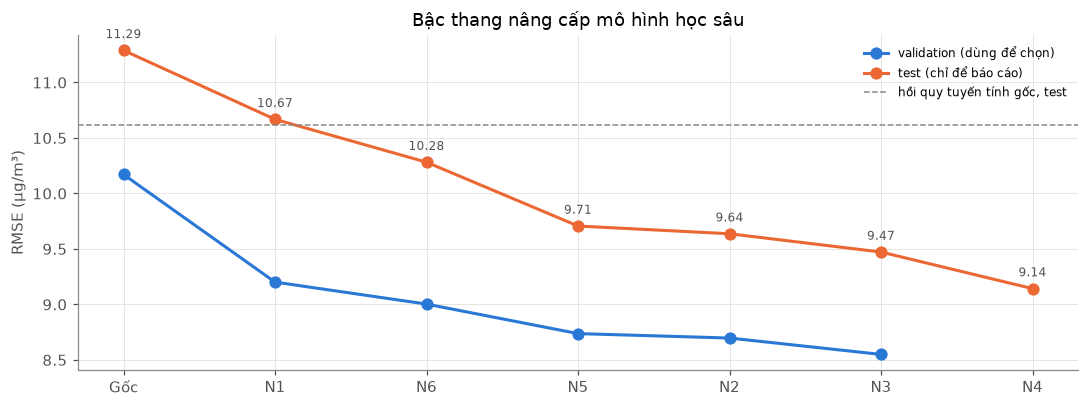

In [35]:
if RUN_EXPERIMENTS:
    def mean_rmse(runs, split, use=False):
        return np.mean([rmse_of(r, split, smear_factor(r["log"]["train"], r["truth"]["train"]) if use else 1.0)
                        for r in runs])

    def ensemble_rmse(runs, split, use):
        lp = mean_log(runs, split)
        k = smear_factor(mean_log(runs, "train"), truth_all["train"]) if use else 1.0
        return scores(truth_all[split].reindex(lp.index), ugm3(lp, k))["RMSE"]

    dl_final = candidates["Học sâu nâng cấp"]["test"]
    ladder = [
        ("Gốc: LSTM + Attention, F15, seed 42", e1_table.loc["LSTM + Attention", "RMSE validation"],
         e1_table.loc["LSTM + Attention", "RMSE"]),
        ("N1: " + describe(best1), mean_rmse(n1_runs[describe(best1)], "validation"), mean_rmse(n1_runs[describe(best1)], "test")),
        ("N6: " + best6_label, mean_rmse(n6_runs[best6_label], "validation"), mean_rmse(n6_runs[best6_label], "test")),
        ("N5: " + describe(final_spec), mean_rmse(final_runs, "validation"), mean_rmse(final_runs, "test")),
        ("N2: hiệu chỉnh sai lệch" + ("" if use_smear_dl else " (không dùng)"),
         mean_rmse(final_runs, "validation", use_smear_dl), mean_rmse(final_runs, "test", use_smear_dl)),
        ("N3: gộp 3 seed", ensemble_rmse(final_runs, "validation", use_smear_dl), ensemble_rmse(final_runs, "test", use_smear_dl)),
        ("N4: huấn luyện lại trên train + validation", np.nan,
         scores(truth_all["test"].reindex(dl_final.index), dl_final)["RMSE"]),
    ]
    ladder_table = pd.DataFrame(ladder, columns=["bậc", "RMSE validation", "RMSE test"]).set_index("bậc")
    ladder_table.to_csv(os.path.join(RESULT_DIR, "N_ladder.csv"))
    display(ladder_table.round(3))

    fig, ax = plt.subplots(figsize=(10, 3.8))
    x = np.arange(len(ladder_table))
    ax.plot(x, ladder_table["RMSE validation"], marker="o", markersize=7, linewidth=2, color=PALETTE[0],
            label="validation (dùng để chọn)")
    ax.plot(x, ladder_table["RMSE test"], marker="o", markersize=7, linewidth=2, color=PALETTE[1],
            label="test (chỉ để báo cáo)")
    ax.axhline(e1_table.loc["Hồi quy tuyến tính", "RMSE"], color="#8a8984", linestyle="--", linewidth=1,
               label="hồi quy tuyến tính gốc, test")
    for i, v in enumerate(ladder_table["RMSE test"]):
        ax.annotate(f"{v:.2f}", (i, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color="#52514e")
    ax.set_xticks(x, ["Gốc", "N1", "N6", "N5", "N2", "N3", "N4"])
    ax.set(ylabel="RMSE (µg/m³)", title="Bậc thang nâng cấp mô hình học sâu")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "N_ladder.png"), bbox_inches="tight")
    plt.show()

**Nhận xét kết quả cuối.**
- **Học sâu nâng cấp thắng chắc chắn mọi mô hình so sánh trên test:** RMSE 9,14, NSE 0,919, MAE 5,91 µg/m³.
  - So với hồi quy tuyến tính gốc (10,62): chênh −1,48, khoảng tin cậy 95% từ −1,77 đến −1,18.
  - So với LSTM + Attention gốc (11,29): chênh −2,15.
  - Sai lệch trung bình chỉ còn −0,70 µg/m³ (bản gốc: −3,98).
- **Hụt đỉnh giảm rõ:** khi PM2.5 thực tế trên 75 µg/m³, sai lệch từ −14,1 (LSTM + Attention gốc) còn −5,3 µg/m³ và MAE từ 16,6 xuống 11,2. Độ dốc đường khớp tăng từ 0,81 lên 0,91, nhỉnh hơn cả hồi quy tuyến tính (0,90).
- **Kết quả giữ được trên dữ liệu 01–10/2026**, có trọn một mùa đông và chưa dùng lần nào: RMSE 9,47, so với 10,68 của hồi quy tuyến tính gốc và 11,05 của LSTM + Attention gốc.
- **Mỗi bậc nâng cấp đều làm RMSE test giảm theo:** 11,29 → 10,67 → 10,28 → 9,71 → 9,64 → 9,47 → 9,14, dù test không được dùng để chọn. Hai bậc giúp nhiều nhất là N1 (đổi sang GRU + Attention học phần thay đổi) và N5 (mạng 2 lớp, 128 unit). Huấn luyện lại trên train + validation (N4) giảm thêm 0,33.
- **Bản trộn với hồi quy tuyến tính** (chọn theo validation) ngang bản chỉ có học sâu: trên test chênh +0,09, khoảng tin cậy chứa 0; trên 2026 bản trộn nhỉnh hơn một chút (9,40 so với 9,47).
- **Hồi quy tuyến tính nâng cấp lại kém bản gốc trên test** (11,41 so với 10,62, khác 0 rõ ràng), dù tốt hơn trên validation (9,69 so với 9,94). Lý do là 10 biến mới giúp nhẹ trên validation nhưng không giữ được trên test. Đây là ví dụ cho thấy chọn theo validation vẫn có rủi ro khi chênh lệch nhỏ.

### 14.10. Vòng 2: thêm các thay đổi nhỏ (N7–N10)

Vòng 1 đã đưa RMSE test từ 11,29 xuống 9,14. Vòng 2 thử thêm các thay đổi nhỏ. Mỗi thay đổi được so với cấu hình cuối của vòng 1 trên validation, mỗi cách 3 seed:

| Mã | Thay đổi | Lý do |
|---|---|---|
| N7a | Giảm tốc độ học một nửa khi loss validation chững 3 epoch | mô hình cuối đạt tốt nhất ngay ở epoch 6, có thể đang học quá nhanh |
| N7b | Tốc độ học 0,0003 thay vì 0,001 | như trên |
| N7c | Dropout 0,3 thay vì 0,2 | chống học vẹt mạnh hơn |
| N8 | GRU hai chiều (BiGRU) đọc cửa sổ 24 giờ | mạng hai chiều của chương 7; mọi giờ trong cửa sổ đều là quá khứ nên đọc hai chiều vẫn hợp lệ |
| N9 | Tăng trọng số cho giờ ô nhiễm cao, tỉ lệ với căn bậc hai của PM2.5 | mô hình vẫn còn hụt đỉnh |

Các thay đổi giúp được trên validation được gộp lại và chạy 3 seed. Sau đó N10 thử gộp nhiều mô hình hơn (5 seed; thêm một kiến trúc), chọn lại trọng số trộn với hồi quy tuyến tính và hiệu chỉnh sai lệch như N3, rồi huấn luyện lại trên train + validation như N4. Tập test đã được nhìn một lần ở mục 14.9; vòng 2 vẫn chỉ chọn theo validation và báo cáo test ở mục 14.12.

In [36]:
def build_v2(sp):
    # Như build_general, thêm: mạng hai chiều (bidir) và tỉ lệ dropout
    RNN = {"gru": layers.GRU, "lstm": layers.LSTM}[sp["cell"]]
    wrap = layers.Bidirectional if sp.get("bidir") else (lambda layer: layer)
    inp = keras.Input(shape=(sp["lookback"], len(FEATS[sp["feat"]])), name="window")
    z = inp
    for _ in range(sp["layers"] - 1):
        z = wrap(RNN(sp["units"], return_sequences=True))(z)
    if sp["attention"]:
        H = wrap(RNN(sp["units"], return_sequences=True))(z)
        h_last = H[:, -1, :]
        context, _ = BahdanauAttention(sp["units"], name="attention")(h_last, H)
        z = layers.Concatenate()([context, h_last])
    else:
        z = wrap(RNN(sp["units"]))(z)
    out = layers.Dense(1)(layers.Dropout(sp.get("dropout", 0.2))(z))
    if sp["residual"]:
        out = layers.Add()([inp[:, -1, 0:1], out])
    return keras.Model(inp, out)


def name_v2(sp, seed):
    tags = [tag for tag, on in [("bi", sp.get("bidir")), (f"do{sp.get('dropout', 0.2)}", sp.get("dropout", 0.2) != 0.2),
                                (f"lr{sp.get('lr', LEARNING_RATE)}", sp.get("lr", LEARNING_RATE) != LEARNING_RATE),
                                ("plateau", sp.get("plateau")), ("wpeak", sp.get("weighted"))] if on]
    return "v2_" + run_name(sp, seed) + "".join("_" + tag for tag in tags)


def peak_weights(pm):
    w = np.sqrt(pm / pm.mean())                      # giờ ô nhiễm cao có trọng số lớn hơn
    return (w / w.mean()).astype("float32")


def fit_v2(name, sp, X, y, pm, seed, epochs, validation=None, lr_list=None):
    keras.utils.set_random_seed(seed)
    model = build_v2(sp)
    model.compile(optimizer=keras.optimizers.Adam(sp.get("lr", LEARNING_RATE)), loss="mse")
    weight_path = os.path.join(MODEL_DIR, f"{name}.weights.h5")
    history_path = os.path.join(MODEL_DIR, f"{name}_history.json")
    if os.path.exists(weight_path) and not RETRAIN:
        model.load_weights(weight_path)
        with open(history_path) as f:
            history = json.load(f)
    else:
        callbacks = []
        if validation is not None:
            callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True))
            if sp.get("plateau"):
                callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5))
        elif lr_list:                                # huấn luyện lại: lặp lại đúng lịch tốc độ học đã dùng
            callbacks.append(keras.callbacks.LearningRateScheduler(lambda epoch, lr: lr_list[min(epoch, len(lr_list) - 1)]))
        start = time.time()
        H = model.fit(X, y, sample_weight=peak_weights(pm) if sp.get("weighted") else None, validation_data=validation,
                      epochs=epochs, batch_size=BATCH_SIZE, verbose=0, callbacks=callbacks)
        history = {k: [float(v) for v in vals] for k, vals in H.history.items()}
        history["train_time_s"] = time.time() - start
        model.save_weights(weight_path)
        with open(history_path, "w") as f:
            json.dump(history, f)
    return model, history


def run_v2(sp, seed=SEED):
    d = windows_of(sp)
    model, history = fit_v2(name_v2(sp, seed), sp, d["train"]["X"], d["train"]["y"], d["train"]["y_true"], seed, EPOCHS,
                            validation=(d["validation"]["X"], d["validation"]["y"]))
    best = int(np.argmin(history["val_loss"])) + 1
    print(f"{name_v2(sp, seed)}: {len(history['loss'])} epoch, tốt nhất ở epoch {best}, {history['train_time_s'] / 60:.1f} phút")
    log, truth = predictions(model, sp, d)
    return {"spec": sp, "seed": seed, "best_epoch": best, "history": history, "log": log, "truth": truth}


def run_full_v2(r):
    if "history" not in r:                           # mô hình của vòng 1: dùng lại hàm ở mục 14.8
        return run_full(r)
    sp = r["spec"]
    d = windows_of(sp)
    X = np.concatenate([d["train"]["X"], d["validation"]["X"]])
    y = np.concatenate([d["train"]["y"], d["validation"]["y"]])
    pm = np.concatenate([d["train"]["y_true"], d["validation"]["y_true"]])
    lr_list = r["history"].get("learning_rate") if sp.get("plateau") else None
    model, _ = fit_v2(name_v2(sp, r["seed"]) + "_full", sp, X, y, pm, r["seed"], r["best_epoch"], lr_list=lr_list)
    print(f"{name_v2(sp, r['seed'])}_full: {r['best_epoch']} epoch trên train + validation")
    log, truth = predictions(model, sp, d)
    return {"spec": sp, "seed": r["seed"], "log": log, "truth": truth}


def peak_bias(runs, split="validation"):
    out = []
    for r in runs:
        y = r["truth"][split]
        out.append(float(np.mean((ugm3(r["log"][split]) - y)[y > 75])))
    return np.mean(out)

In [37]:
if RUN_EXPERIMENTS:
    base2 = dict(final_spec)
    v2_variants = {"N7a: giảm tốc độ học khi chững": {**base2, "plateau": True},
                   "N7b: tốc độ học 0,0003": {**base2, "lr": 3e-4},
                   "N7c: dropout 0,3": {**base2, "dropout": 0.3},
                   "N8: BiGRU": {**base2, "bidir": True},
                   "N9: trọng số cho giờ ô nhiễm cao": {**base2, "weighted": True}}
    v2_runs = {"cấu hình cuối vòng 1": final_runs}
    for label, sp in v2_variants.items():
        v2_runs[label] = [run_v2(sp, s) for s in SEEDS3]

    base_val = np.mean([rmse_of(r) for r in final_runs])
    helpful = [label for label in v2_variants if np.mean([rmse_of(r) for r in v2_runs[label]]) < base_val]
    lr_pair = ["N7a: giảm tốc độ học khi chững", "N7b: tốc độ học 0,0003"]
    if set(lr_pair) <= set(helpful):                  # hai cách cùng đổi tốc độ học: chỉ giữ cách tốt hơn
        helpful.remove(max(lr_pair, key=lambda l: np.mean([rmse_of(r) for r in v2_runs[l]])))
    if len(helpful) >= 2:
        combo = dict(base2)
        for label in helpful:
            combo.update({k: v for k, v in v2_variants[label].items() if k not in base2})
        v2_runs["gộp " + " + ".join(l.split(":")[0] for l in helpful)] = [run_v2(combo, s) for s in SEEDS3]

    v2_rows = []
    for label, runs in v2_runs.items():
        v = [rmse_of(r) for r in runs]
        v2_rows.append({"thay đổi": label, "RMSE validation TB": np.mean(v), "độ lệch chuẩn": np.std(v, ddof=1),
                        "sai lệch khi PM2.5 > 75": peak_bias(runs)})
    v2_table = pd.DataFrame(v2_rows).set_index("thay đổi")
    v2_table.to_csv(os.path.join(RESULT_DIR, "N7_N9_changes.csv"))
    best2_label = v2_table["RMSE validation TB"].idxmin()
    best2_runs = v2_runs[best2_label]
    best2_spec = best2_runs[0]["spec"]
    display(v2_table.round(3))
    print("Giúp được trên validation:", helpful or "không có")
    print("Chọn sau vòng 2:", best2_label)

v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed42_plateau: 16 epoch, tốt nhất ở epoch 6, 1.6 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed43_plateau: 18 epoch, tốt nhất ở epoch 8, 1.8 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed44_plateau: 18 epoch, tốt nhất ở epoch 8, 1.9 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed42_lr0.0003: 28 epoch, tốt nhất ở epoch 18, 2.9 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed43_lr0.0003: 39 epoch, tốt nhất ở epoch 29, 4.0 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed44_lr0.0003: 38 epoch, tốt nhất ở epoch 28, 4.0 phút


... (7 outputs left out)

v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed43_wpeak: 23 epoch, tốt nhất ở epoch 13, 2.5 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed44_wpeak: 18 epoch, tốt nhất ở epoch 8, 2.1 phút


,RMSE validation TB,độ lệch chuẩn,sai lệch khi PM2.5 > 75
thay đổi,,,
cấu hình cuối vòng 1,8.737,0.134,-5.200
N7a: giảm tốc độ học khi chững,8.737,0.134,-5.200
"N7b: tốc độ học 0,0003",8.870,0.028,-5.244
"N7c: dropout 0,3",8.752,0.101,-5.198
N8: BiGRU,8.761,0.121,-4.059
N9: trọng số cho giờ ô nhiễm cao,8.684,0.101,-4.725


Giúp được trên validation: ['N9: trọng số cho giờ ô nhiễm cao']
Chọn sau vòng 2: N9: trọng số cho giờ ô nhiễm cao


**Nhận xét N7–N9.**
- **Chỉ N9 giúp được trên validation.** Tăng trọng số cho giờ ô nhiễm cao giảm RMSE từ 8,74 xuống 8,68, và giảm hụt đỉnh: sai lệch khi PM2.5 trên 75 từ −5,2 còn −4,7 µg/m³.
- **N7a không đổi gì:** mô hình đạt tốt nhất ở epoch 6, trước khi tốc độ học kịp giảm. Các epoch sau với tốc độ học nhỏ hơn không vượt được epoch 6, nên trọng số được giữ lại y hệt bản gốc.
- **N7b, N7c và N8 đều kém đi chút ít** (RMSE 8,75–8,87):
  - N7b: tốc độ học nhỏ hơn;
  - N7c: dropout lớn hơn;
  - N8: BiGRU. Bản này giảm hụt đỉnh rõ nhất (−4,1), nhưng RMSE chung không tốt hơn và chạy chậm gấp đôi.
- Vì chỉ một thay đổi giúp được nên không cần chạy bản gộp; cấu hình sau vòng 2 là N9.

### 14.11. N10: gộp nhiều mô hình hơn

So ba cách gộp trên validation: 3 seed như vòng 1; 5 seed; 5 seed cộng thêm 3 seed của GRU học phần thay đổi (không attention, cùng siêu tham số). Sau đó chọn lại trọng số trộn với hồi quy tuyến tính và hiệu chỉnh sai lệch như N3.

In [38]:
if RUN_EXPERIMENTS:
    run_same = run if best2_label == "cấu hình cuối vòng 1" else run_v2
    five = best2_runs + [run_same(best2_spec, s) for s in (45, 46)]
    gru_spec = {**best2_spec, "attention": False}
    gru_runs = [run_v2(gru_spec, s) for s in SEEDS3]
    ensembles = {"3 seed": best2_runs, "5 seed": five, "5 seed + GRU học phần thay đổi (3 seed)": five + gru_runs}

    n10_rows = []
    for label, members in ensembles.items():
        for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
            for use in (False, True):
                lp = blend(mean_log(members, "validation"), lin_run["log"]["validation"], w)
                k = smear_factor(blend(mean_log(members, "train"), lin_run["log"]["train"], w), truth_all["train"]) if use else 1.0
                n10_rows.append({"cách gộp": label, "w (học sâu)": w, "hiệu chỉnh": "có" if use else "không", "hệ số k": k,
                                 **scores(truth_all["validation"].reindex(lp.index), ugm3(lp, k))})
    n10_table = pd.DataFrame(n10_rows).set_index(["cách gộp", "w (học sâu)", "hiệu chỉnh"])
    n10_table.to_csv(os.path.join(RESULT_DIR, "N10_ensembles.csv"))
    ens2_label, w2, smear2 = n10_table["RMSE"].idxmin()
    smear2 = smear2 == "có"
    only_dl = n10_table.xs(1.0, level="w (học sâu)")["RMSE"]
    ens2_dl_label, smear2_dl = only_dl.idxmin()
    smear2_dl = smear2_dl == "có"
    display(n10_table.xs(1.0, level="w (học sâu)").round(3))
    print(f"Chỉ học sâu, tốt nhất: {ens2_dl_label} (hiệu chỉnh = {smear2_dl}) | "
          f"tốt nhất khi được trộn: {ens2_label}, w = {w2}, hiệu chỉnh = {smear2}")

v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed45_wpeak: 20 epoch, tốt nhất ở epoch 10, 2.2 phút


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed46_wpeak: 22 epoch, tốt nhất ở epoch 12, 2.4 phút


v2_n_ext_gru_res_F15_lb24_u128_l2_seed42_wpeak: 21 epoch, tốt nhất ở epoch 11, 2.1 phút


v2_n_ext_gru_res_F15_lb24_u128_l2_seed43_wpeak: 23 epoch, tốt nhất ở epoch 13, 2.3 phút


v2_n_ext_gru_res_F15_lb24_u128_l2_seed44_wpeak: 18 epoch, tốt nhất ở epoch 8, 1.8 phút


hệ số k     R2    NSE  \
cách gộp                                hiệu chỉnh                          
3 seed                                  không         1.000  0.930  0.930   
                                        có            0.999  0.930  0.930   
5 seed                                  không         1.000  0.931  0.931   
                                        có            0.997  0.931  0.931   
5 seed + GRU học phần thay đổi (3 seed) không         1.000  0.932  0.931   
                                        có            0.998  0.932  0.931   

                                                      MAE   RMSE  
cách gộp                                hiệu chỉnh                
3 seed                                  không       5.669  8.470  
                                        có          5.674  8.474  
5 seed                                  không       5.602  8.381  
                                        có          5.613  8.392  
5 seed + GRU học phần thay đổi (3 seed) không       5.593  8.369  
                                        có          5.602  8.378

Chỉ học sâu, tốt nhất: 5 seed + GRU học phần thay đổi (3 seed) (hiệu chỉnh = False) | tốt nhất khi được trộn: 5 seed + GRU học phần thay đổi (3 seed), w = 0.75, hiệu chỉnh = True


**Nhận xét N10.**
- **Nếu chỉ dùng học sâu**, gộp càng nhiều mô hình càng tốt: 3 seed cho RMSE validation 8,47, 5 seed 8,38, thêm 3 seed GRU học phần thay đổi 8,37. Chọn cách gộp 8 mô hình. Hiệu chỉnh sai lệch không còn cần (hệ số $k \approx 1$), vì N9 đã làm dự báo bớt thấp.
- **Trộn thêm 25% hồi quy tuyến tính** vẫn tốt nhất trên validation (8,30), như vòng 1.

### 14.12. Kết quả vòng 2 trên test

Các mô hình của cách gộp đã chọn được huấn luyện lại trên train + validation (như N4). Bảng so mô hình cuối của vòng 2 với vòng 1 và với hồi quy tuyến tính gốc, trên test và trên 01–10/2026.

In [39]:
if RUN_EXPERIMENTS:
    members2 = ensembles[ens2_dl_label]
    full2 = [run_full_v2(r) for r in members2]

    def final_v2(members_full, w, use, split):
        lp = blend(mean_log(members_full, split), lin_full["log"][split], w)
        fit = pd.concat([blend(mean_log(members_full, s), lin_full["log"][s], w) for s in ("train", "validation")])
        return ugm3(lp, smear_factor(fit, fit_truth) if use else 1.0)

    candidates2 = {"Hồi quy tuyến tính (gốc)": candidates["Hồi quy tuyến tính (gốc)"],
                   "Học sâu nâng cấp vòng 1": candidates["Học sâu nâng cấp"],
                   "Học sâu nâng cấp vòng 2": {s: final_v2(full2, 1.0, smear2_dl, s) for s in ("test", "test_2026")}}
    if 0 < w2 < 1:
        members2_mix = ensembles[ens2_label]
        full2_mix = full2 if members2_mix is members2 else [run_full_v2(r) for r in members2_mix]
        candidates2[f"Trộn vòng 2 (w = {w2})"] = {s: final_v2(full2_mix, w2, smear2, s) for s in ("test", "test_2026")}
    rows = []
    for name, p in candidates2.items():
        yt, y26 = truth_all["test"].reindex(p["test"].index), truth_all["test_2026"].reindex(p["test_2026"].index)
        mt, m26 = scores(yt, p["test"]), scores(y26, p["test_2026"])
        high = yt > 75
        rows.append({"mô hình": name, "R2 test": mt["R2"], "NSE test": mt["NSE"], "MAE test": mt["MAE"], "RMSE test": mt["RMSE"],
                     "sai lệch khi PM2.5 > 75": float(np.mean((p["test"] - yt)[high])),
                     "NSE 2026": m26["NSE"], "RMSE 2026": m26["RMSE"]})
    final2_table = pd.DataFrame(rows).set_index("mô hình")
    final2_table.to_csv(os.path.join(RESULT_DIR, "N_round2_final.csv"))
    display(final2_table.round(3))

    arr2 = {name: p["test"].reindex(order_t).to_numpy() for name, p in candidates2.items()}
    r2_rows = []
    for a, b in [("Học sâu nâng cấp vòng 2", "Học sâu nâng cấp vòng 1"), ("Học sâu nâng cấp vòng 2", "Hồi quy tuyến tính (gốc)")]:
        lo, hi = boot_ci(arr2[a], arr2[b], "RMSE")
        r2_rows.append({"so sánh": f"{a} so với {b}", "chênh lệch RMSE": scores(y_test, arr2[a])["RMSE"] - scores(y_test, arr2[b])["RMSE"],
                        "khoảng tin cậy 95%": f"{lo:+.3f} đến {hi:+.3f}", "khác 0 rõ ràng?": "có" if lo > 0 or hi < 0 else "chưa chắc"})
    boot2_table = pd.DataFrame(r2_rows).set_index("so sánh")
    boot2_table.to_csv(os.path.join(RESULT_DIR, "N_round2_bootstrap.csv"))
    display(boot2_table)

v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed42_wpeak_full: 11 epoch trên train + validation


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed43_wpeak_full: 13 epoch trên train + validation


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed44_wpeak_full: 8 epoch trên train + validation


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed45_wpeak_full: 10 epoch trên train + validation


v2_n_ext_gruatt_res_F15_lb24_u128_l2_seed46_wpeak_full: 12 epoch trên train + validation


v2_n_ext_gru_res_F15_lb24_u128_l2_seed42_wpeak_full: 11 epoch trên train + validation


v2_n_ext_gru_res_F15_lb24_u128_l2_seed43_wpeak_full: 13 epoch trên train + validation


v2_n_ext_gru_res_F15_lb24_u128_l2_seed44_wpeak_full: 8 epoch trên train + validation


,R2 test,NSE test,MAE test,RMSE test,sai lệch khi PM2.5 > 75,NSE 2026,RMSE 2026
mô hình,,,,,,,
Hồi quy tuyến tính (gốc),0.892,0.891,6.985,10.621,-6.599,0.874,10.679
Học sâu nâng cấp vòng 1,0.919,0.919,5.909,9.143,-5.335,0.901,9.471
Học sâu nâng cấp vòng 2,0.921,0.921,5.889,9.038,-5.782,0.904,9.307
Trộn vòng 2 (w = 0.75),0.920,0.919,6.022,9.156,-6.888,0.905,9.233


,chênh lệch RMSE,khoảng tin cậy 95%,khác 0 rõ ràng?
so sánh,,,
Học sâu nâng cấp vòng 2 so với Học sâu nâng cấp vòng 1,-0.104609,-0.220 đến +0.011,chưa chắc
Học sâu nâng cấp vòng 2 so với Hồi quy tuyến tính (gốc),-1.583093,-1.922 đến -1.231,có


**Nhận xét vòng 2.**
- **Mô hình cuối của vòng 2** đạt RMSE test 9,04, NSE 0,921, MAE 5,89 µg/m³; trên 2026, RMSE 9,31. Vòng 1 là 9,14 và 9,47.
- **Cải thiện so với vòng 1 nhỏ và chưa chắc là thật:** RMSE giảm 0,10, khoảng tin cậy từ −0,22 đến +0,01. So với hồi quy tuyến tính gốc thì vẫn thắng chắc chắn: RMSE thấp hơn 1,58 (từ 1,23 đến 1,92).
- **Bản trộn với hồi quy tuyến tính** (chọn theo validation) kém hơn chút trên test (9,16) nhưng nhỉnh hơn trên 2026 (9,23); hai cách gần như ngang nhau.
- **Các thay đổi nhỏ đã bắt đầu hết tác dụng:** mỗi bước chỉ còn giúp vài phần trăm RMSE, cỡ dao động giữa các seed.

### 14.13. Còn nâng cấp được bao nhiêu? Sai số theo giờ trong ngày

Mục 2.1 cho thấy CAMS nối hai lượt dự báo lúc 7:00 và 19:00 giờ Hà Nội, nên ở hai giờ này PM2.5 có bước nhảy mà số liệu quá khứ không báo trước được. Bảng dưới tính RMSE của mô hình cuối theo giờ cần dự báo.

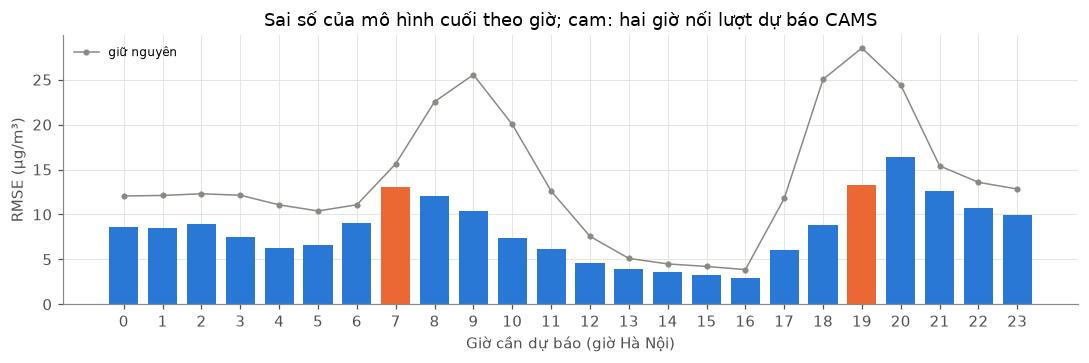

Hai giờ 7:00 và 19:00 chiếm 8% số giờ nhưng 18% tổng bình phương sai số.
RMSE cả tập test: 9.04; nếu bỏ hai giờ này: 8.57 µg/m³.


In [40]:
if RUN_EXPERIMENTS:
    p = candidates2["Học sâu nâng cấp vòng 2"]["test"]
    y = truth_all["test"].reindex(p.index)
    persist = candidates["Giữ nguyên (persistence)"]["test"].reindex(p.index)
    hour = (p.index + pd.Timedelta(hours=HORIZON)).hour
    err = pd.DataFrame({"giờ": hour, "mô hình": (p - y).to_numpy() ** 2, "giữ nguyên": (persist - y).to_numpy() ** 2})
    hour_table = err.groupby("giờ").mean() ** 0.5
    hour_table.to_csv(os.path.join(RESULT_DIR, "N_error_by_hour.csv"))
    stitch = np.isin(hour, [7, 19])
    share = err["mô hình"][stitch].sum() / err["mô hình"].sum()
    rmse_rest = np.sqrt(err["mô hình"][~stitch].mean())

    fig, ax = plt.subplots(figsize=(10, 3.4))
    colors = [PALETTE[1] if h in (7, 19) else PALETTE[0] for h in hour_table.index]
    ax.bar(hour_table.index, hour_table["mô hình"], color=colors, width=0.75)
    ax.plot(hour_table.index, hour_table["giữ nguyên"], color="#8a8984", marker="o", markersize=3, linewidth=1, label="giữ nguyên")
    ax.set(xlabel="Giờ cần dự báo (giờ Hà Nội)", ylabel="RMSE (µg/m³)", xticks=range(0, 24),
           title="Sai số của mô hình cuối theo giờ; cam: hai giờ nối lượt dự báo CAMS")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "N_error_by_hour.png"), bbox_inches="tight")
    plt.show()
    print(f"Hai giờ 7:00 và 19:00 chiếm {2 / 24:.0%} số giờ nhưng {share:.0%} tổng bình phương sai số.")
    print(f"RMSE cả tập test: {np.sqrt(err['mô hình'].mean()):.2f}; nếu bỏ hai giờ này: {rmse_rest:.2f} µg/m³.")

**Nhận xét.**
- **Sai số dồn vào sáng sớm và tối:** RMSE cao nhất ở các giờ cần dự báo 7–8 giờ và 19–21 giờ (12–16 µg/m³), thấp nhất ở 12–16 giờ (3–5 µg/m³).
- **Lý do:** đây là các giờ PM2.5 đổi nhanh, lại trùng với hai giờ CAMS nối lượt dự báo (7:00 và 19:00).
  - Riêng hai giờ nối lượt chiếm 8% số giờ nhưng 18% tổng bình phương sai số; bỏ hai giờ này thì RMSE giảm từ 9,04 xuống 8,57 µg/m³.
  - Bước nhảy ở hai giờ này đến từ lượt dự báo mới của CAMS, không có trong số liệu quá khứ, nên không mô hình nào đoán trước được.
- **Ở chính các giờ đổi nhanh, mô hình hơn "giữ nguyên" nhiều nhất** (ví dụ 18 giờ: RMSE 8,8 so với 25,0).
- **Kết luận:** muốn giảm sai số đáng kể nữa cần thông tin mới, ví dụ dự báo thời tiết hoặc bản dự báo của chính CAMS cho các giờ tới, chứ không phải tinh chỉnh thêm mô hình trên cùng dữ liệu.

## 15. Tổng hợp kết quả

In [41]:
summary = {"E1_test": e1_table.to_dict(orient="index"),
           "attention": attention_stats,
           "seeds": {f"{a} / {b}": v for (a, b), v in seed_summary.round(4).to_dict().items()},
           "bias_test_main": float(np.mean(p_main - y_test)),
           "error_by_level": level_table.round(4).to_dict(orient="index"),
           "bootstrap": {" / ".join(k): v for k, v in boot_table.to_dict(orient="index").items()}}
if RUN_EXPERIMENTS:
    summary["E2_lookback"] = e2_table.to_dict(orient="index")
    summary["E3_features"] = e3_table.to_dict(orient="index")
    summary["units"] = unit_table.to_dict(orient="index")
    summary["E1b_residual"] = e1b_table.reset_index().to_dict(orient="records")
    summary["E1b_compare_3_seeds"] = compare.to_dict(orient="index")
    summary["E1b_bootstrap"] = {" / ".join(k): v for k, v in e1b_boot.to_dict(orient="index").items()}
    summary["N_choice"] = {"N1": describe(best1), "N6": best6_label, "N5": describe(final_spec),
                           "linear": describe(lin_spec), "smear_dl": use_smear_dl, "smear_linear": use_smear_lin,
                           "w": float(w_star), "smear_blend": bool(smear_star)}
    summary["N1"] = n1_table.drop(columns="spec").to_dict(orient="records")
    summary["N1_seeds"] = n1_seed_table.to_dict(orient="index")
    summary["N6"] = n6_table.to_dict(orient="index")
    summary["N5"] = n5_table.drop(columns="spec").to_dict(orient="records")
    summary["N5_seeds"] = n5_seed_table.to_dict(orient="index")
    summary["N_linear"] = lin_table.drop(columns="spec").head(10).to_dict(orient="records")
    summary["N2"] = {" / ".join(k): v for k, v in n2_table.to_dict(orient="index").items()}
    summary["N3"] = {f"w={a} / {b}": v for (a, b), v in n3_table.to_dict(orient="index").items()}
    summary["N_final"] = final_table.to_dict(orient="index")
    summary["N_bootstrap"] = {" / ".join(k): v for k, v in n_boot.to_dict(orient="index").items()}
    summary["N_ladder"] = ladder_table.to_dict(orient="index")
    summary["N_peaks"] = peak_table.to_dict(orient="index")
    summary["N7_N9"] = v2_table.to_dict(orient="index")
    summary["N10"] = {" / ".join(map(str, k)): v for k, v in n10_table.to_dict(orient="index").items()}
    summary["N_round2_final"] = final2_table.to_dict(orient="index")
    summary["N_round2_bootstrap"] = boot2_table.to_dict(orient="index")
    summary["N_error_by_hour"] = hour_table.to_dict(orient="index")
    summary["N_round2_choice"] = {"helpful": helpful, "best": best2_label, "ensemble": ens2_dl_label, "smear": bool(smear2_dl),
                                  "mix": [ens2_label, float(w2), bool(smear2)]}
with open(os.path.join(RESULT_DIR, "task1_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
print(sorted(os.listdir(RESULT_DIR)))
print(sorted(os.listdir(FIG_DIR)))

['E1_model_comparison.csv', 'E1b_bootstrap.csv', 'E1b_residual.csv', 'E2_lookback.csv', 'E3_features.csv', 'N10_ensembles.csv', 'N1_screening.csv', 'N1_three_seeds.csv', 'N2_smearing.csv', 'N3_ensemble.csv', 'N5_grid.csv', 'N5_three_seeds.csv', 'N6_data.csv', 'N7_N9_changes.csv', 'N_bootstrap.csv', 'N_error_by_hour.csv', 'N_final_comparison.csv', 'N_ladder.csv', 'N_linear.csv', 'N_peaks.csv', 'N_round2_bootstrap.csv', 'N_round2_final.csv', 'bootstrap_differences.csv', 'error_by_month.csv', 'persistence_baseline.csv', 'seeds.csv', 'task1_summary.json', 'units.csv']
['E1_model_comparison.png', 'N_error_by_hour.png', 'N_ladder.png', 'attention_by_lag.png', 'eda_correlation.png', 'eda_pm25_autocorrelation.png', 'eda_pm25_cycles.png', 'eda_pm25_distribution.png', 'eda_pm25_timeseries.png', 'eda_pm25_vs_weather.png', 'final_model_architecture.png', 'forecast_example.png', 'main_learning_curve.png', 'scatter_pred_vs_true.png']


## 16. Kết luận

1. **Học sâu thắng chắc chắn các mô hình mốc đơn giản.** LSTM + Attention dự báo PM2.5 2 giờ tới với R² 0,900, NSE 0,876, MAE 7,37, RMSE 11,29 µg/m³ trên test, tốt hơn hẳn "giữ nguyên" (NSE 0,765, RMSE 15,55); bootstrap xác nhận chênh lệch này.
2. **Với cấu hình ban đầu, hồi quy tuyến tính trên cùng cửa sổ vẫn tốt nhất trên test** (NSE 0,891, RMSE 10,62), vì PM2.5 2 giờ sau gần như là tổ hợp tuyến tính của vài giờ gần nhất. Cho mạng chỉ học phần thay đổi (E1b) đưa GRU về ngang hồi quy tuyến tính (RMSE 10,90, chênh lệch chưa chắc khác 0) nhưng chưa vượt được.
3. **Attention không làm chính xác hơn LSTM**, chỉ làm kết quả ổn định hơn qua các seed. Trọng số dồn vào vài giờ gần nhất và cùng giờ hôm trước.
4. **Ít đặc trưng lại tốt hơn** (E3): chỉ PM2.5 và thời gian cho RMSE test 10,31. Độ dài cửa sổ và số unit ít ảnh hưởng.
5. **Hạn chế:**
   - mô hình hụt đỉnh ô nhiễm (độ dốc 0,81; thấp hơn thực tế 14 µg/m³ khi PM2.5 trên 75);
   - PM2.5 là số của mô hình CAMS, không phải số đo trạm;
   - E2, E3 và số unit mới chạy một seed;
   - validation và test khác nhau nhiều, nên cải thiện trên validation chưa chắc giữ được trên test.
6. **Sau mười bước nâng cấp (mục 14), học sâu thắng chắc chắn hồi quy tuyến tính.** Mô hình cuối là GRU + Attention học phần thay đổi:
   - 2 lớp, 128 unit, cửa sổ 24 giờ;
   - dữ liệu train từ 08/2022, có trọng số cho giờ ô nhiễm cao;
   - gộp 5 seed với 3 seed của bản GRU không attention, huấn luyện lại trên train + validation.

   Trên test, mô hình đạt NSE 0,921 và RMSE 9,04 µg/m³, so với 0,891 và 10,62 của hồi quy tuyến tính. Trên dữ liệu 01–10/2026, RMSE là 9,31 so với 10,68.
7. **Task 1 đã gần trần với dữ liệu hiện có.** Vòng 2 chỉ cải thiện thêm 0,1 RMSE và chưa chắc khác 0. Phần sai số còn lại chủ yếu nằm ở các giờ PM2.5 đổi nhanh và hai giờ CAMS nối lượt dự báo (mục 14.13).